# Perfis de saúde e contexto social (NHIS 2025): K-modes e HAC

## Objetivo

Criar **grupos de pessoas** com poucas variáveis bem escolhidas e entender **como a depressão se distribui entre eles**. É uma análise exploratória feita do zero: os agrupamentos anteriores usavam dezenas de variáveis (inclusive ansiedade e o código `-1` como categoria), o que dificultava enxergar o que separava os grupos.

Perguntas:

1. Existem perfis de **saúde física e funcionalidade**? E de **contexto psicossocial e financeiro**?
2. K-modes e HAC chegam a grupos parecidos?
3. Os grupos são "reais" (estáveis e acima do que o acaso produziria) ou apenas cortes de um contínuo?
4. A prevalência de depressão muda entre os grupos? Quais sinais físicos pesam?

**Hipótese do projeto:** dados físicos e funcionais carregam informação sobre depressão. A análise exploratória (`02 Análise exploratória/07_associacao_depressao_variaveis_nao_mentais_2025.ipynb`) indicou que o sinal vem de dor, limitações e autoavaliação de saúde, e não do diagnóstico de doenças crônicas clássicas.

## Decisões de desenho

1. **Sintomas de depressão e ansiedade ficam de fora** (25 colunas). A depressão **não participa** da formação dos grupos: só é usada depois, para descrevê-los.
2. **Poucas variáveis, em dois blocos temáticos**, escolhidas com apoio da análise exploratória (seção 1): saúde física e funcionalidade (bloco 1) e contexto psicossocial e financeiro (bloco 2).
3. Cada variável vira um **indicador 0/1** (um "sinal de atenção", como *dor na maioria dos dias*). A distância entre duas pessoas passa a ser o número de indicadores em que diferem. É a lógica do K-modes, e a HAC usa a mesma geometria.
4. **`-1` significa "não respondeu"** e não vira categoria: registros com ausência em algum indicador ficam de fora (cerca de 2%).
5. **Idade e demais características só descrevem os grupos.** O peso amostral também não entra na formação dos grupos: serve apenas para ponderar as estimativas de depressão e de população.
6. Não confiamos no silhouette sozinho: medimos a **estabilidade** dos grupos e comparamos tudo com **dados embaralhados** (mesmas frequências, sem associações), que mostram o que o acaso produz.

**Execução:** requer o pacote `kmodes` (`pip install kmodes`) e leva cerca de 8 minutos, quase todo gasto nos diagnósticos das seções 4 e 5.

## Como funcionam os métodos

- **K-modes:** cada grupo é representado pelo perfil mais comum (a *moda*). O algoritmo move as pessoas entre grupos até minimizar o total de discordâncias com a moda do próprio grupo.
- **HAC (Ward):** começa com cada pessoa isolada e junta, passo a passo, os grupos cuja fusão menos aumenta a variância interna. Cortamos a hierarquia em *k* grupos. Em dados 0/1, a distância euclidiana ao quadrado é o número de discordâncias, a mesma medida do K-modes.
- **Por que a HAC usa amostras:** ela precisa de uma matriz de distâncias *n × n* (cerca de 2 GiB com 23 mil registros). Montamos a hierarquia em amostras aleatórias de 6.000 registros e atribuímos todos os registros ao centroide mais próximo.
- **ARI (índice de Rand ajustado):** compara duas partições. 0 é o acordo esperado ao acaso e 1 é partição idêntica.

# 1. Dados e escolha das variáveis

## 1.1 Carga dos dados

A base limpa é lida de `01 Preparação dos dados/dados/limpos/adult25_limpo.csv`. Mantemos os registros com severidade PHQ definida e criamos o alvo binário (`0` = sem depressão, `1` = com depressão, como nos modelos supervisionados). O alvo só será usado para **descrever** os grupos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from kmodes.kmodes import KModes
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.stats import chi2_contingency
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score

sns.set_theme(style='whitegrid', palette='deep')
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.width', 200)

RANDOM_STATE = 42
K_FINAL = 5
KS_DIAGNOSTICO = range(2, 9)
N_AMOSTRAS = 4
TAMANHO_AMOSTRA = 6000
TAMANHO_SILHOUETTE = 3000
N_INIT_DIAGNOSTICO = 5
N_INIT_FINAL = 30
REPETICOES_EMBARALHADO = 3
REPETICOES_BOOTSTRAP = 1000
MIN_REGISTROS_CELULA = 50

PASTA_IMAGENS = Path('../repositorio imagens/04 Modelos não supervisionados/09_perfis_kmodes_hac_2025')
PASTA_IMAGENS.mkdir(parents=True, exist_ok=True)


def salvar_figura(nome_arquivo):
    plt.gcf().savefig(PASTA_IMAGENS / nome_arquivo, dpi=150, bbox_inches='tight')


CAMINHO_CSV = Path('01 Preparação dos dados') / 'dados' / 'limpos' / 'adult25_limpo.csv'
arquivo_csv = next((p / CAMINHO_CSV for p in (Path('.'), Path('..'), Path('../..')) if (p / CAMINHO_CSV).exists()), None)
if arquivo_csv is None:
    raise FileNotFoundError(f'Não foi possível encontrar {CAMINHO_CSV}. Execute o notebook a partir da sua própria pasta.')

ID_COLUNA = 'ID_DOMICILIO'
PESO = 'PESO_AMOSTRAL'
ALVO = 'SEVERIDADE_DEPRESSAO_PHQ'

# Sintomas de depressão (PHQ) e ansiedade (GAD-7): nunca entram na formação dos grupos
COLUNAS_SINTOMAS = [
    'FREQ_PERDA_INTERESSE_2SEM', 'FREQ_SENTIU_DEPRIMIDO_2SEM',
    'FREQ_DIFICULDADE_DORMIR_2SEM', 'FREQ_CANSASO_2SEM',
    'FREQ_HIPOREXIA_COMPULSAO_ALIMENTAR_2SEM', 'FREQ_AUTOAVALIACAO_NEGTIVA_2SEM',
    'FREQ_DIFICULDADE_CONCENTRACAO_2SEM', 'MODIFICACAO_VELOCIDADE_FALA',
    'FREQ_DEPRESSAO', 'REMEDIO_DEPRESSAO', 'HISTORICO_DEPRESSAO',
    'INTENSIDADE_DEPRESSAO', 'SEVERIDADE_DEPRESSAO_PHQ',
    'HISTORICO_TRANSTORNO_ANSIEDADE', 'MED_ANSIEDADE',
    'FREQ_ANSIEDADE', 'INTENSIDADE_ANSIEDADE',
    'FREQ_ANSIEDADE_2SEM', 'FREQ_PREOCUPACAO_INCONTROLAVEL_2SEM',
    'FREQ_PREOCUPACAO_DESNECESSARIA_2SEM', 'FREQ_DIFICULDADE_DESCANSAR_2SEM',
    'FREQ_AGITACAO_INQUIETA', 'FREQ_IRRITABILIDADE_2SEM',
    'FREQ_MEDO_2SEM', 'SEVERIDADE_ANSIEDADE',
]

# Variáveis candidatas, organizadas como na análise exploratória (notebook 07)
GRUPOS = {
    'Saúde física': [
        'CATEGORIA_IMC', 'HISTORICO_COLESTEROL', 'HISTORICO_DIABETES', 'HISTORICO_HIPERTENSAO',
        'HISTORICO_ARTRITE', 'ASMA_ATIVA_ATUALMENTE', 'TEVE_CANCER', 'DOR_CRONICA',
        'CONCUSSAO_SINTOMAS_POS_TRAUMA', 'JA_FUMANTE', 'AUTOAVALIACAO_SAUDE_GERAL',
    ],
    'Funcional e cognitiva': [
        'DIFICULDADE_LOCOMOCAO', 'LIMITACAO_TRABALHO_POR_SAUDE', 'DEFICIENTE',
        'FREQUENCIA_FALHA_MEMORIA', 'TIPO_DIFICULDADE_COGNITIVA', 'QTD_DIFICULDADE_COGNITIVA',
    ],
    'Vínculos e família': [
        'ESTADO_CIVIL_DECLARADO', 'ESTADO_CIVIL', 'STATUS_PARENTAL', 'SEXO_CONJUGE',
        'SEPARACAO_LEGAL_CONJUGAL', 'COJUGE_TRABALHA', 'FLG_IDOSO_FAMILIA',
        'QTD_ADULTOS_FAMILIA', 'QTD_CRIANÇAS_FAMILIA', 'SUPORTE_SOCIAL', 'FREQ_SOLITARIO',
    ],
    'Socioeconômica': [
        'ESCOLARIDADE_MAXIMA_FAMILIA', 'TEMPO_MORADIA_ANOS', 'TIPO_POSSE_IMOVEL',
        'CATEGORIA_RAZAO_POBREZA', 'RAZAO_RENDA_POBREZA', 'RENDA_INVESTIMENTOS',
        'ESTRESSE_FINANCEIRO_MEDICO',
    ],
    'Uso de serviços de saúde': [
        'ULTIMA_VISITA_MEDICO', 'VISITAS_PRONTO_ATENDIMENTO_12M', 'VISITAS_EMERGENCIA_HOSPITALAR_12M',
        'VISITAS_EXAME_VISTA_12M', 'PLANO_PUBLICO', 'PLANO_PRIVADO',
    ],
    'Demográfica': [
        'IDADE', 'SEXO', 'NATURAL_ESTADOS_UNIDOS', 'CLASSIFICACAO_URBANO_RURAL', 'REGIAO_GEOGRAFICA',
    ],
}

dados = pd.read_csv(arquivo_csv)
total_registros = len(dados)

ausentes = [c for c in COLUNAS_SINTOMAS if c not in dados.columns]
assert not ausentes, f'Colunas de sintomas inexistentes na base: {ausentes}'
agrupadas = [c for colunas in GRUPOS.values() for c in colunas]
assert len(agrupadas) == len(set(agrupadas)), 'Há variável repetida nos grupos'
assert set(agrupadas) == set(dados.columns) - {ID_COLUNA, PESO} - set(COLUNAS_SINTOMAS), 'Variáveis fora dos grupos'

dados = dados[~dados[ALVO].isin([-1, 5])].copy()
dados['DEPRESSAO'] = (dados[ALVO] != 1).astype(int)

print(f'Registros na base limpa: {total_registros:,} | com severidade PHQ definida: {len(dados):,}')
print(f"Prevalência de depressão: {dados['DEPRESSAO'].mean():.1%} (simples) | "
      f"{np.average(dados['DEPRESSAO'], weights=dados[PESO]):.1%} (ponderada pelo peso amostral)")
print(f'Variáveis candidatas: {len(agrupadas)} em {len(GRUPOS)} grupos (sintomas de saúde mental excluídos: {len(COLUNAS_SINTOMAS)})')

Registros na base limpa: 24,215 | com severidade PHQ definida: 23,619
Prevalência de depressão: 21.2% (simples) | 21.4% (ponderada pelo peso amostral)
Variáveis candidatas: 46 em 6 grupos (sintomas de saúde mental excluídos: 25)


## 1.2 Quais variáveis entram?

Usamos a análise exploratória como guia, com quatro critérios:

1. **Associação com a depressão**, medida pelo V de Cramér (mesma métrica e mesma discretização do notebook 07). O grupo *Funcional e cognitiva* teve o maior V médio (0,32), seguido por *Saúde física*, *Socioeconômica* e *Vínculos e família* (cerca de 0,12 cada). *Uso de serviços* (0,07) e *Demográfica* (0,05) quase não se associam.
2. **Não repetir informação.** Por exemplo, a razão renda/pobreza e sua categoria têm correlação de 0,98 (notebook 05), e o tipo e a frequência de dificuldade cognitiva só existem para quem relata dificuldade.
3. **Não ser consequência do que queremos descrever.** Uso de serviços reflete saúde e acesso, não uma condição de vida.
4. **Ser interpretável e ter pouca ausência.**

As doenças crônicas clássicas (diabetes, hipertensão, colesterol, câncer) têm associação desprezível com a depressão quando analisadas uma a uma. Para não descartá-las, elas entram **resumidas em um único indicador**: ter duas ou mais condições crônicas.

23 de 47 variáveis têm V ≥ 0,10 ou foram usadas; as demais têm associação desprezível.


,Variável,Grupo na análise exploratória,V de Cramér,Papel neste estudo
0,FREQ_SOLITARIO,Vínculos e família,0.398,Usada no bloco 2
1,TIPO_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.395,Fora: repete QTD_DIFICULDADE_COGNITIVA (só vale para quem relata dificuldade)
2,QTD_DIFICULDADE_COGNITIVA,Funcional e cognitiva,0.385,Usada no bloco 2
3,FREQUENCIA_FALHA_MEMORIA,Funcional e cognitiva,0.347,Fora: repete QTD_DIFICULDADE_COGNITIVA (só vale para quem relata dificuldade)
4,AUTOAVALIACAO_SAUDE_GERAL,Saúde física,0.317,Usada no bloco 1
5,DOR_CRONICA,Saúde física,0.305,Usada no bloco 1
6,SUPORTE_SOCIAL,Vínculos e família,0.275,Usada no bloco 2
7,LIMITACAO_TRABALHO_POR_SAUDE,Funcional e cognitiva,0.271,Usada no bloco 1
8,DEFICIENTE,Funcional e cognitiva,0.266,Fora: derivada de itens funcionais já usados
9,DIFICULDADE_LOCOMOCAO,Funcional e cognitiva,0.235,Usada no bloco 1


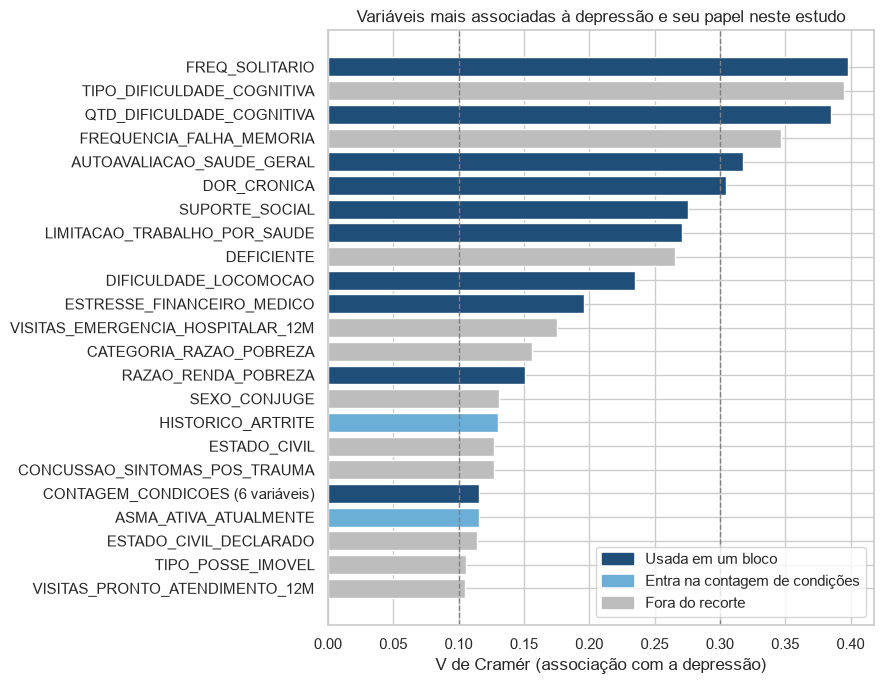

In [2]:
def discretizar(coluna):
    serie = dados[coluna].replace(-1, np.nan)
    if coluna == 'IDADE':
        return pd.cut(serie, [17, 29, 39, 49, 59, 69, 120])
    if coluna == 'RAZAO_RENDA_POBREZA':
        return pd.qcut(serie, 5, duplicates='drop')
    return serie


def cramers_v(tabela):
    chi2, _, _, _ = chi2_contingency(tabela, correction=False)
    n = tabela.to_numpy().sum()
    linhas, colunas = tabela.shape
    phi2 = max(0.0, chi2 / n - (colunas - 1) * (linhas - 1) / (n - 1))
    linhas_corr = linhas - (linhas - 1) ** 2 / (n - 1)
    colunas_corr = colunas - (colunas - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / min(colunas_corr - 1, linhas_corr - 1)))


CONDICOES = ['HISTORICO_COLESTEROL', 'HISTORICO_DIABETES', 'HISTORICO_HIPERTENSAO',
             'HISTORICO_ARTRITE', 'ASMA_ATIVA_ATUALMENTE', 'TEVE_CANCER']
contagem_condicoes = (dados[CONDICOES] == 1).sum(axis=1).where((dados[CONDICOES] != -1).all(axis=1))

linhas = []
for grupo, colunas in GRUPOS.items():
    for coluna in colunas:
        tabela = pd.crosstab(discretizar(coluna), dados['DEPRESSAO'])
        if tabela.shape[0] >= 2:
            linhas.append({'Variável': coluna, 'Grupo na análise exploratória': grupo, 'V de Cramér': cramers_v(tabela)})
linhas.append({
    'Variável': 'CONTAGEM_CONDICOES (6 variáveis)', 'Grupo na análise exploratória': 'Saúde física',
    'V de Cramér': cramers_v(pd.crosstab(contagem_condicoes.clip(upper=3), dados['DEPRESSAO'])),
})
associacao = pd.DataFrame(linhas)

BLOCO_DE_ORIGEM = {
    'AUTOAVALIACAO_SAUDE_GERAL': 1, 'DOR_CRONICA': 1, 'DIFICULDADE_LOCOMOCAO': 1, 'LIMITACAO_TRABALHO_POR_SAUDE': 1,
    'CONTAGEM_CONDICOES (6 variáveis)': 1,
    'FREQ_SOLITARIO': 2, 'SUPORTE_SOCIAL': 2, 'QTD_DIFICULDADE_COGNITIVA': 2,
    'ESTRESSE_FINANCEIRO_MEDICO': 2, 'RAZAO_RENDA_POBREZA': 2,
}
PAPEL_ESPECIFICO = {
    'TIPO_DIFICULDADE_COGNITIVA': 'Fora: repete QTD_DIFICULDADE_COGNITIVA (só vale para quem relata dificuldade)',
    'FREQUENCIA_FALHA_MEMORIA': 'Fora: repete QTD_DIFICULDADE_COGNITIVA (só vale para quem relata dificuldade)',
    'DEFICIENTE': 'Fora: derivada de itens funcionais já usados',
    'CATEGORIA_RAZAO_POBREZA': 'Fora: duplica a razão renda/pobreza (ρ = 0,98, notebook 05)',
}
PAPEL_POR_GRUPO = {
    'Saúde física': 'Fora: fator de risco com associação pequena',
    'Funcional e cognitiva': 'Fora: repete itens funcionais já usados',
    'Vínculos e família': 'Fora: associação pequena e ligada à idade',
    'Socioeconômica': 'Fora: associação pequena',
    'Uso de serviços de saúde': 'Fora: uso de serviços reflete saúde e acesso',
    'Demográfica': 'Fora: só descreve os grupos',
}


def papel(linha):
    if linha['Variável'] in BLOCO_DE_ORIGEM:
        return f"Usada no bloco {BLOCO_DE_ORIGEM[linha['Variável']]}"
    if linha['Variável'] in CONDICOES:
        return 'Entra na contagem de condições (bloco 1)'
    if linha['Variável'] in PAPEL_ESPECIFICO:
        return PAPEL_ESPECIFICO[linha['Variável']]
    return PAPEL_POR_GRUPO[linha['Grupo na análise exploratória']]


associacao['Papel neste estudo'] = associacao.apply(papel, axis=1)
associacao = associacao.sort_values('V de Cramér', ascending=False).reset_index(drop=True)
relevantes = associacao[(associacao['V de Cramér'] >= 0.10) | associacao['Papel neste estudo'].str.startswith('Usada')]
print(f"{len(relevantes)} de {len(associacao)} variáveis têm V ≥ 0,10 ou foram usadas; as demais têm associação desprezível.")
display(relevantes.round({'V de Cramér': 3}).reset_index(drop=True))

cores = {'Usada': '#1f4e79', 'Entra': '#6baed6', 'Fora': '#bdbdbd'}
grafico = relevantes.iloc[::-1]
plt.figure(figsize=(9, 7))
plt.barh(grafico['Variável'], grafico['V de Cramér'],
         color=[cores[p.split(' ')[0].rstrip(':')] for p in grafico['Papel neste estudo']])
plt.axvline(0.1, color='gray', linestyle='--', linewidth=1)
plt.axvline(0.3, color='gray', linestyle='--', linewidth=1)
plt.xlabel('V de Cramér (associação com a depressão)')
plt.title('Variáveis mais associadas à depressão e seu papel neste estudo')
plt.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cores.values()],
           labels=['Usada em um bloco', 'Entra na contagem de condições', 'Fora do recorte'], loc='lower right')
plt.tight_layout()
salvar_figura('01_selecao_variaveis.png')
plt.show()

### Leitura da seleção

- As variáveis mais associadas à depressão são as mesmas da análise exploratória: solidão (V = 0,40), tipo e quantidade de dificuldade cognitiva (0,39 e 0,40), falha de memória (0,35), saúde autoavaliada (0,32) e dor crônica (0,31).
- Dos três itens cognitivos, usamos só a quantidade de dificuldade (`QTD_DIFICULDADE_COGNITIVA`). `DEFICIENTE` (0,27) ficou de fora por ser derivada dos itens funcionais que já entram, e `CATEGORIA_RAZAO_POBREZA` duplica a razão numérica.
- A contagem de condições crônicas tem V = 0,12, o menor entre as variáveis usadas. Ela entra para testar diretamente a ideia de "doenças físicas", e não por ser um preditor forte.
- **Cuidado de interpretação:** como escolhemos variáveis que se associam à depressão, é esperado que os grupos formados com elas difiram em depressão. Isso **não é uma descoberta independente**. O que o estudo pode mostrar é *quais combinações* de sinais concentram a depressão, se há **estrutura de grupos** de verdade e se o resultado resiste às checagens, inclusive a um controle com variáveis sem relação com a depressão (seção 7).

# 2. Indicadores de atenção e base de análise

Cada variável selecionada vira um indicador 0/1 com um **corte usual**, e o `-1` (não respondeu) vira ausente. Os indicadores formam dois blocos:

- **Bloco 1, saúde física e funcionalidade:** saúde autoavaliada, dor, mobilidade, limitação para trabalhar e multimorbidade.
- **Bloco 2, contexto psicossocial e financeiro:** solidão, suporte social, dificuldade cognitiva, preocupação financeira com a saúde e renda.

Dificuldade cognitiva e solidão são os sinais mais próximos de sintomas depressivos (dificuldade de concentração e isolamento fazem parte do quadro). Por isso ficam no bloco 2, e uma checagem posterior (seção 7) os retira.

In [3]:
def sinal(coluna, regra):
    serie = dados[coluna]
    return regra(serie).astype(float).where(serie != -1)


BLOCO_1 = ['Saúde regular ou ruim', 'Dor na maioria dos dias', 'Dificuldade de locomoção',
           'Limitação no trabalho', '2+ condições crônicas']
BLOCO_2 = ['Solidão (às vezes ou mais)', 'Pouco suporte social', 'Dificuldade cognitiva',
           'Preocupação financeira', 'Renda < 2x a pobreza']

indicadores = pd.DataFrame({
    'Saúde regular ou ruim': sinal('AUTOAVALIACAO_SAUDE_GERAL', lambda s: s <= 2),
    'Dor na maioria dos dias': sinal('DOR_CRONICA', lambda s: s >= 3),
    'Dificuldade de locomoção': sinal('DIFICULDADE_LOCOMOCAO', lambda s: s >= 2),
    'Limitação no trabalho': sinal('LIMITACAO_TRABALHO_POR_SAUDE', lambda s: s == 1),
    '2+ condições crônicas': (contagem_condicoes >= 2).astype(float).where(contagem_condicoes.notna()),
    'Solidão (às vezes ou mais)': sinal('FREQ_SOLITARIO', lambda s: s >= 3),
    'Pouco suporte social': sinal('SUPORTE_SOCIAL', lambda s: s <= 3),
    'Dificuldade cognitiva': sinal('QTD_DIFICULDADE_COGNITIVA', lambda s: s >= 2),
    'Preocupação financeira': sinal('ESTRESSE_FINANCEIRO_MEDICO', lambda s: s >= 2),
    'Renda < 2x a pobreza': sinal('RAZAO_RENDA_POBREZA', lambda s: s < 2),
})[BLOCO_1 + BLOCO_2]

REGRAS = {
    'Saúde regular ou ruim': ('AUTOAVALIACAO_SAUDE_GERAL', 'saúde autoavaliada regular ou ruim (códigos 1 e 2)'),
    'Dor na maioria dos dias': ('DOR_CRONICA', 'dor na maioria dos dias ou todos os dias nos últimos 3 meses'),
    'Dificuldade de locomoção': ('DIFICULDADE_LOCOMOCAO', 'alguma, muita dificuldade ou incapacidade (códigos 2 a 4)'),
    'Limitação no trabalho': ('LIMITACAO_TRABALHO_POR_SAUDE', 'problema de saúde limita o trabalho (código 1)'),
    '2+ condições crônicas': ('6 variáveis de histórico', 'colesterol, diabetes, hipertensão, artrite, asma ativa e câncer: 2 ou mais'),
    'Solidão (às vezes ou mais)': ('FREQ_SOLITARIO', 'solidão às vezes, geralmente ou sempre (códigos 3 a 5)'),
    'Pouco suporte social': ('SUPORTE_SOCIAL', 'recebe suporte nunca, raramente ou às vezes (códigos 1 a 3)'),
    'Dificuldade cognitiva': ('QTD_DIFICULDADE_COGNITIVA', 'alguma dificuldade para lembrar ou se concentrar (códigos 2 a 4)'),
    'Preocupação financeira': ('ESTRESSE_FINANCEIRO_MEDICO', 'alguma ou muita preocupação com contas médicas (códigos 2 e 3)'),
    'Renda < 2x a pobreza': ('RAZAO_RENDA_POBREZA', 'renda familiar menor que o dobro da linha de pobreza'),
}

completos = indicadores.notna().all(axis=1)
base = dados.loc[completos].reset_index(drop=True)
ind = indicadores.loc[completos].reset_index(drop=True).astype(int)

y = base['DEPRESSAO'].to_numpy()
w = base[PESO].to_numpy(dtype=float)
idade = base['IDADE'].where(base['IDADE'] >= 0)
faixa_etaria = pd.cut(idade, [17, 29, 44, 59, 74, 120], labels=['18-29', '30-44', '45-59', '60-74', '75+'])
prevalencia_geral = np.average(y, weights=w)

tabela_regras = pd.DataFrame({
    'Bloco': [1] * 5 + [2] * 5,
    'Indicador (= 1 quando)': [f'{nome}: {REGRAS[nome][1]}' for nome in BLOCO_1 + BLOCO_2],
    'Variável no CSV': [REGRAS[nome][0] for nome in BLOCO_1 + BLOCO_2],
    '% na amostra': [100 * ind[nome].mean() for nome in BLOCO_1 + BLOCO_2],
    '% ponderada': [100 * np.average(ind[nome], weights=w) for nome in BLOCO_1 + BLOCO_2],
})
display(tabela_regras.round(1))

perdidos = indicadores.isna().sum()
print(f'Registros com depressão definida: {len(dados):,} | completos nos 10 indicadores: {len(base):,} ({len(base) / len(dados):.1%}) | excluídos: {len(dados) - len(base):,}')
print('Ausências por indicador:', {nome: int(qtd) for nome, qtd in perdidos.items() if qtd})
print(f'Prevalência de depressão na base de análise: {y.mean():.1%} (simples) | {prevalencia_geral:.1%} (ponderada)')

,Bloco,Indicador (= 1 quando),Variável no CSV,% na amostra,% ponderada
0,1,Saúde regular ou ruim: saúde autoavaliada regular ou ruim (códigos 1 e 2),AUTOAVALIACAO_SAUDE_GERAL,15.3,14.3
1,1,Dor na maioria dos dias: dor na maioria dos dias ou todos os dias nos últimos 3 meses,DOR_CRONICA,23.6,20.6
2,1,"Dificuldade de locomoção: alguma, muita dificuldade ou incapacidade (códigos 2 a 4)",DIFICULDADE_LOCOMOCAO,23.3,18.7
3,1,Limitação no trabalho: problema de saúde limita o trabalho (código 1),LIMITACAO_TRABALHO_POR_SAUDE,21.0,18.2
4,1,"2+ condições crônicas: colesterol, diabetes, hipertensão, artrite, asma ativa e câncer: 2 ou mais",6 variáveis de histórico,39.3,32.0
5,2,"Solidão (às vezes ou mais): solidão às vezes, geralmente ou sempre (códigos 3 a 5)",FREQ_SOLITARIO,26.4,24.5
6,2,"Pouco suporte social: recebe suporte nunca, raramente ou às vezes (códigos 1 a 3)",SUPORTE_SOCIAL,19.8,18.7
7,2,Dificuldade cognitiva: alguma dificuldade para lembrar ou se concentrar (códigos 2 a 4),QTD_DIFICULDADE_COGNITIVA,26.7,25.1
8,2,Preocupação financeira: alguma ou muita preocupação com contas médicas (códigos 2 e 3),ESTRESSE_FINANCEIRO_MEDICO,41.6,44.2
9,2,Renda < 2x a pobreza: renda familiar menor que o dobro da linha de pobreza,RAZAO_RENDA_POBREZA,26.2,26.4


Registros com depressão definida: 23,619 | completos nos 10 indicadores: 23,155 (98.0%) | excluídos: 464
Ausências por indicador: {'Saúde regular ou ruim': 6, 'Dor na maioria dos dias': 67, 'Dificuldade de locomoção': 4, 'Limitação no trabalho': 26, '2+ condições crônicas': 145, 'Solidão (às vezes ou mais)': 183, 'Pouco suporte social': 227, 'Dificuldade cognitiva': 7, 'Preocupação financeira': 40}
Prevalência de depressão na base de análise: 21.1% (simples) | 21.3% (ponderada)


## 2.1 Os indicadores formam dois blocos?

A matriz abaixo mostra a correlação entre os indicadores (coeficiente phi, que é a correlação de Pearson entre variáveis 0/1). A última linha e a última coluna trazem a **depressão**, que **não entrou** na formação dos grupos e só serve de referência. Se os indicadores de um bloco se associam entre si mais do que com os do outro, faz sentido agrupá-los separadamente.

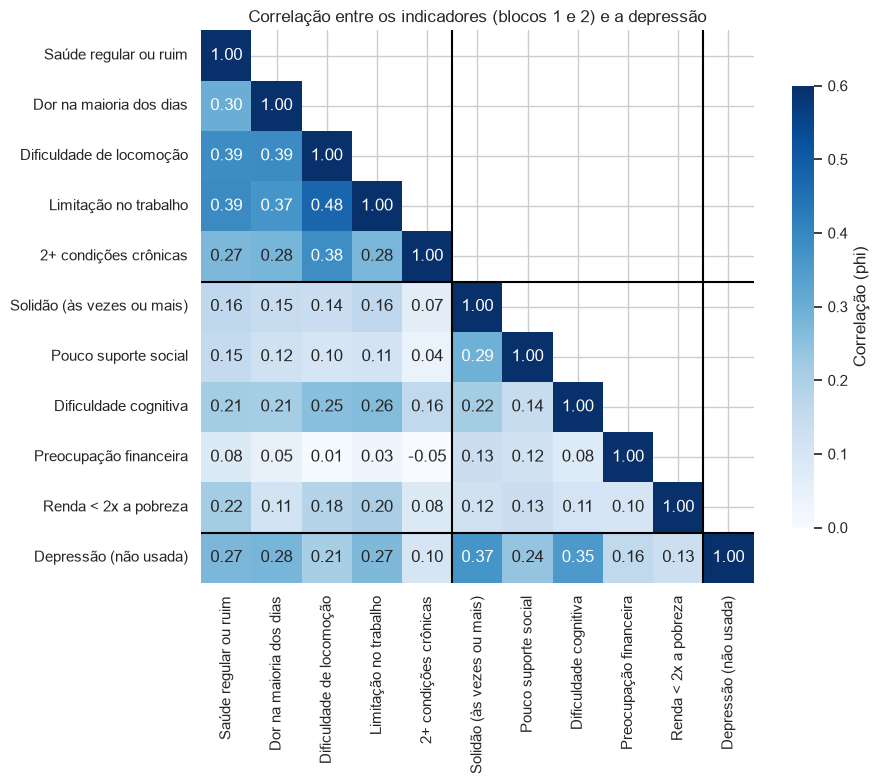

Correlação média dentro do bloco 1: 0.35 | dentro do bloco 2: 0.14 | entre os blocos: 0.13


In [4]:
matriz = ind.assign(**{'Depressão (não usada)': y}).corr()
mascara = np.triu(np.ones_like(matriz, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(matriz, mask=mascara, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=0.6, square=True,
            cbar_kws={'label': 'Correlação (phi)', 'shrink': 0.8})
plt.axhline(5, color='black', linewidth=1.5)
plt.axvline(5, color='black', linewidth=1.5)
plt.axhline(10, color='black', linewidth=1.5)
plt.axvline(10, color='black', linewidth=1.5)
plt.title('Correlação entre os indicadores (blocos 1 e 2) e a depressão')
plt.tight_layout()
salvar_figura('02_correlacao_indicadores.png')
plt.show()

dentro_1 = matriz.loc[BLOCO_1, BLOCO_1].to_numpy()[np.triu_indices(5, k=1)].mean()
dentro_2 = matriz.loc[BLOCO_2, BLOCO_2].to_numpy()[np.triu_indices(5, k=1)].mean()
entre = matriz.loc[BLOCO_1, BLOCO_2].to_numpy().mean()
print(f'Correlação média dentro do bloco 1: {dentro_1:.2f} | dentro do bloco 2: {dentro_2:.2f} | entre os blocos: {entre:.2f}')

### Leitura

- **Os indicadores do bloco 1 andam juntos:** a correlação média entre eles é 0,35 (de 0,27 a 0,48). Quem tem dificuldade de locomoção costuma ter também limitação no trabalho (0,48), saúde regular ou ruim (0,39) e dor frequente (0,39).
- **No bloco 2 quase não andam:** a correlação média cai para 0,14, praticamente igual à correlação **entre** os dois blocos (0,13). Solidão e pouco suporte social formam o par mais ligado (0,29). A preocupação financeira se associa pouco a todos os demais (no máximo 0,13), e a renda baixa se liga mais aos sinais físicos (até 0,22, com saúde regular ou ruim) do que aos do próprio bloco (até 0,13).
- Isso antecipa o resultado: o bloco 1 tem chance de formar perfis, e o bloco 2 dificilmente forma grupos distintos.
- **Depressão (última linha):** todos os indicadores se correlacionam positivamente com ela, de 0,10 a 0,37. Solidão (0,37) e dificuldade cognitiva (0,35) lideram, seguidas por dor (0,28), saúde regular ou ruim (0,27), limitação no trabalho (0,27) e pouco suporte social (0,24). Ter 2+ condições crônicas é o indicador mais fraco (0,10).

# 3. Funções de apoio

- **`diagnosticar`:** para cada *k*, mede custo, silhouette, estabilidade e tamanho do menor grupo nos dois métodos. A estabilidade usa a mesma regra para ambos: ajusta o método em 4 amostras aleatórias de 6.000 registros, atribui **todos** os registros a um grupo e compara as partições (ARI médio). O silhouette usa a distância de Hamming (discordâncias) em 3.000 registros sorteados.
- **`calibrar_com_embaralhados`:** repete as medidas em dados em que cada coluna foi embaralhada de forma independente (mesmas frequências, sem associações). Mostra o que o acaso produz.
- **`tabela_grupos` e `painel_perfis`:** descrevem cada grupo (sinais predominantes, tamanho, depressão ponderada pelo peso amostral com IC de 95% por bootstrap, idade). Os grupos são numerados do **menor para o maior número de sinais**.
- **`comparar_metodos`, `grupos_vs_contagem` e demais:** comparação K-modes × HAC e checagens.

O IC por bootstrap ignora o desenho amostral complexo da pesquisa; serve para dar uma ideia da incerteza, não como inferência formal.

In [5]:
def kmodes_ajustar(X, k, n_init, semente):
    return KModes(n_clusters=k, init='Huang', n_init=n_init, random_state=semente, n_jobs=1).fit(X)


def arvore_ward(X, amostra):
    return linkage(X[amostra].astype(float), method='ward')


def hac_rotulos(arvore, X, amostra, k):
    corte = cut_tree(arvore, n_clusters=k).ravel()
    centroides = np.vstack([X[amostra][corte == c].mean(axis=0) for c in range(k)])
    return ((X[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2).argmin(axis=1)


def sortear_amostras(n, semente=RANDOM_STATE):
    return [np.random.default_rng(semente + i).choice(n, TAMANHO_AMOSTRA, replace=False) for i in range(N_AMOSTRAS)]


def media_ari(lista_rotulos):
    aris = [adjusted_rand_score(lista_rotulos[i], lista_rotulos[j])
            for i in range(len(lista_rotulos)) for j in range(i + 1, len(lista_rotulos))]
    return float(np.mean(aris))


def preparar_amostras(X, semente=RANDOM_STATE):
    amostras = sortear_amostras(len(X), semente)
    arvores = [arvore_ward(X, a) for a in amostras]
    idx_silhouette = np.random.default_rng(semente).choice(len(X), TAMANHO_SILHOUETTE, replace=False)
    return amostras, arvores, idx_silhouette


def custo_por_registro(modelo, X, rotulos):
    return float((X != modelo.cluster_centroids_[rotulos]).sum() / len(X))


def avaliar_estrutura(X, k, preparo, semente=RANDOM_STATE):
    amostras, arvores, idx = preparo
    modelos = [kmodes_ajustar(X[a], k, N_INIT_DIAGNOSTICO, semente + i) for i, a in enumerate(amostras)]
    rot_km = [m.predict(X) for m in modelos]
    rot_h = [hac_rotulos(z, X, a, k) for z, a in zip(arvores, amostras)]
    return {
        'Custo por registro (K-modes)': min(custo_por_registro(m, X, r) for m, r in zip(modelos, rot_km)),
        'Silhouette K-modes': silhouette_score(X[idx], rot_km[0][idx], metric='hamming'),
        'Silhouette HAC': silhouette_score(X[idx], rot_h[0][idx], metric='hamming'),
        'Estabilidade K-modes (ARI)': media_ari(rot_km),
        'Estabilidade HAC (ARI)': media_ari(rot_h),
        'Menor grupo K-modes (%)': 100 * np.bincount(rot_km[0], minlength=k).min() / len(X),
        'Menor grupo HAC (%)': 100 * np.bincount(rot_h[0], minlength=k).min() / len(X),
        'ARI K-modes x HAC': adjusted_rand_score(rot_km[0], rot_h[0]),
    }


def diagnosticar(X, ks, preparo):
    return pd.DataFrame({k: avaliar_estrutura(X, k, preparo) for k in ks}).T.rename_axis('k')


def embaralhar_colunas(X, semente):
    rng = np.random.default_rng(semente)
    return np.column_stack([rng.permutation(X[:, j]) for j in range(X.shape[1])])


def calibrar_com_embaralhados(X, k, real):
    colunas = ['Custo por registro (K-modes)', 'Silhouette K-modes', 'Silhouette HAC',
               'Estabilidade K-modes (ARI)', 'Estabilidade HAC (ARI)']
    nulos = []
    for r in range(REPETICOES_EMBARALHADO):
        Xp = embaralhar_colunas(X, 1000 + r)
        nulos.append(avaliar_estrutura(Xp, k, preparar_amostras(Xp)))
    nulos = pd.DataFrame(nulos)[colunas]
    return pd.DataFrame({
        'Dados reais': real[colunas],
        'Embaralhados (média)': nulos.mean(),
        'Embaralhados (mínimo)': nulos.min(),
        'Embaralhados (máximo)': nulos.max(),
    })


def figura_diagnostico(tabela, titulo, arquivo):
    fig, eixos = plt.subplots(2, 2, figsize=(12, 8))
    ks = tabela.index
    eixos[0, 0].plot(ks, tabela['Custo por registro (K-modes)'], 'o-')
    eixos[0, 0].set(title='Custo do K-modes (melhor de 4 ajustes, em todos os registros)', ylabel='Discordâncias por registro')
    for nome, rotulo in (('Silhouette K-modes', 'K-modes'), ('Silhouette HAC', 'HAC')):
        eixos[0, 1].plot(ks, tabela[nome], 'o-', label=rotulo)
    eixos[0, 1].set(title='Silhouette (distância de Hamming)', ylabel='Silhouette')
    for nome, rotulo in (('Estabilidade K-modes (ARI)', 'K-modes'), ('Estabilidade HAC (ARI)', 'HAC')):
        eixos[1, 0].plot(ks, tabela[nome], 'o-', label=rotulo)
    eixos[1, 0].set(title='Estabilidade entre amostras (ARI médio)', ylabel='ARI', ylim=(0, 1.02))
    for nome, rotulo in (('Menor grupo K-modes (%)', 'K-modes'), ('Menor grupo HAC (%)', 'HAC')):
        eixos[1, 1].plot(ks, tabela[nome], 'o-', label=rotulo)
    eixos[1, 1].axhline(5, color='gray', linestyle='--', linewidth=1)
    eixos[1, 1].set(title='Tamanho do menor grupo', ylabel='% da amostra')
    for eixo in eixos.flat:
        eixo.axvline(K_FINAL, color='gray', linestyle=':')
        eixo.set_xlabel('Número de grupos (k)')
    for eixo in eixos.flat[1:]:
        eixo.legend()
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    salvar_figura(arquivo)
    plt.show()


def ordenar_por_carga(X, rotulos):
    k = rotulos.max() + 1
    carga = np.array([X[rotulos == c].mean(axis=0).sum() if (rotulos == c).any() else np.inf for c in range(k)])
    novo = np.empty(k, dtype=int)
    novo[np.argsort(carga)] = np.arange(k)
    return novo[rotulos]


def prevalencia_ponderada(rotulos, k, indices=None):
    if indices is None:
        indices = np.arange(len(rotulos))
    numerador = np.bincount(rotulos[indices], weights=(w * y)[indices], minlength=k)
    denominador = np.bincount(rotulos[indices], weights=w[indices], minlength=k)
    return numerador / np.where(denominador == 0, np.nan, denominador)


def prevalencia_com_ic(rotulos):
    k = rotulos.max() + 1
    rng = np.random.default_rng(RANDOM_STATE)
    reamostras = np.array([prevalencia_ponderada(rotulos, k, rng.integers(0, len(y), len(y))) for _ in range(REPETICOES_BOOTSTRAP)])
    return prevalencia_ponderada(rotulos, k), np.nanpercentile(reamostras, 2.5, axis=0), np.nanpercentile(reamostras, 97.5, axis=0)


def tabela_grupos(rotulos, prefixo, indicadores_do_bloco):
    k = rotulos.max() + 1
    prev, inferior, superior = prevalencia_com_ic(rotulos)
    populacao = np.bincount(rotulos, weights=w, minlength=k) / w.sum()
    linhas = []
    for c in range(k):
        m = rotulos == c
        predominantes = [nome for nome, p in indicadores_do_bloco[m].mean().items() if p >= 0.5]
        linhas.append({
            'Grupo': f'{prefixo}{c + 1}',
            'Sinais predominantes (≥ 50% do grupo)': ' + '.join(predominantes) if predominantes else 'poucos sinais',
            'n': int(m.sum()),
            '% da amostra': 100 * m.mean(),
            '% da população': 100 * populacao[c],
            'Depressão % (IC 95%)': f'{100 * prev[c]:.1f} ({100 * inferior[c]:.1f}-{100 * superior[c]:.1f})',
            'Idade mediana': idade[m].median(),
            '% com 60+ anos': 100 * (idade[m] >= 60).sum() / idade[m].notna().sum(),
        })
    return pd.DataFrame(linhas).set_index('Grupo')


def painel_perfis(rotulos, prefixo, indicadores_do_bloco, titulo, arquivo):
    k = rotulos.max() + 1
    perfil = pd.DataFrame({f'{prefixo}{c + 1}': 100 * indicadores_do_bloco[rotulos == c].mean() for c in range(k)})
    prev, inferior, superior = prevalencia_com_ic(rotulos)
    rotulos_x = [f'{prefixo}{c + 1}\n{100 * (rotulos == c).mean():.0f}%' for c in range(k)]
    fig, (eixo_perfil, eixo_prev) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.35, 1]})
    sns.heatmap(perfil, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, ax=eixo_perfil,
                cbar_kws={'label': '% do grupo com o sinal'})
    eixo_perfil.set_xticklabels(rotulos_x, rotation=0)
    eixo_perfil.set(title='Perfil de cada grupo', xlabel='Grupo e % da amostra')
    posicoes = np.arange(k)
    eixo_prev.bar(posicoes, 100 * prev, yerr=[100 * (prev - inferior), 100 * (superior - prev)], capsize=4, color='#2a6f97')
    eixo_prev.axhline(100 * prevalencia_geral, color='black', linestyle='--', linewidth=1,
                      label=f'Total: {100 * prevalencia_geral:.1f}%')
    for pos, valor, limite in zip(posicoes, prev, superior):
        eixo_prev.text(pos, 100 * limite + 1.5, f'{100 * valor:.0f}%', ha='center', fontsize=9)
    eixo_prev.set_xticks(posicoes, [f'{prefixo}{c + 1}' for c in range(k)])
    eixo_prev.set(title='Depressão em cada grupo (ponderada, IC 95%)', ylabel='% com depressão', ylim=(0, 100 * superior.max() + 12))
    eixo_prev.legend(loc='upper left')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    salvar_figura(arquivo)
    plt.show()


def figura_dendrograma(arvore, k, titulo, arquivo, ultimas=12):
    corte = (arvore[-k, 2] + arvore[-(k - 1), 2]) / 2
    fig, (eixo_arvore, eixo_alturas) = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.6, 1]})
    dendrogram(arvore, truncate_mode='lastp', p=20, show_leaf_counts=True, leaf_font_size=8, ax=eixo_arvore,
               color_threshold=corte, above_threshold_color='gray')
    eixo_arvore.axhline(corte, color='black', linestyle='--', linewidth=1, label=f'Corte em k = {k}')
    eixo_arvore.set(title='Dendrograma (20 últimos ramos; entre parênteses, nº de registros)', ylabel='Distância de Ward')
    eixo_arvore.legend()
    ks = np.arange(2, ultimas + 2)
    alturas = [arvore[-(j - 1), 2] for j in ks]
    cores = ['#2a6f97' if j == k else '#9ecae1' for j in ks]
    eixo_alturas.bar(ks, alturas, color=cores)
    eixo_alturas.set(title='Altura da fusão que reduz k grupos a k-1', xlabel='k (grupos antes da fusão)', ylabel='Altura')
    fig.suptitle(titulo, fontsize=13)
    plt.tight_layout()
    salvar_figura(arquivo)
    plt.show()
    print('Altura da fusão que reduz k a k-1 grupos (k = 2 a 8):', ', '.join(f'{arvore[-(j - 1), 2]:.1f}' for j in range(2, 9)))


def comparar_metodos(rot_km, rot_h, titulo, arquivo):
    cruzamento = 100 * pd.crosstab(pd.Series(rot_km + 1, name='K-modes'), pd.Series(rot_h + 1, name='HAC'), normalize='index')
    cruzamento.index = [f'K{c}' for c in cruzamento.index]
    cruzamento.columns = [f'H{c}' for c in cruzamento.columns]
    plt.figure(figsize=(6.5, 4.5))
    sns.heatmap(cruzamento, annot=True, fmt='.0f', cmap='Blues', vmin=0, vmax=100, cbar_kws={'label': '% do grupo K-modes'})
    plt.title(titulo)
    plt.tight_layout()
    salvar_figura(arquivo)
    plt.show()
    print(f'ARI entre K-modes e HAC: {adjusted_rand_score(rot_km, rot_h):.2f} | informação mútua normalizada: {normalized_mutual_info_score(rot_km, rot_h):.2f}')


def grupos_vs_contagem(indicadores_do_bloco, solucoes):
    contagem = indicadores_do_bloco.sum(axis=1).to_numpy()
    k = contagem.max() + 1
    tabela = pd.DataFrame({
        'n': np.bincount(contagem, minlength=k),
        'Depressão % (ponderada)': 100 * prevalencia_ponderada(contagem, k),
    }).rename_axis('Nº de sinais no bloco')
    display(tabela.round(1))
    v = {'Nº de sinais (contagem simples)': cramers_v(pd.crosstab(contagem, y))}
    v.update({f'Grupos {nome}': cramers_v(pd.crosstab(rot, y)) for nome, rot in solucoes.items()})
    print('V de Cramér com a depressão:', ' | '.join(f'{nome}: {valor:.3f}' for nome, valor in v.items()))

# 4. Bloco 1: saúde física e funcionalidade

Indicadores: saúde regular ou ruim, dor na maioria dos dias, dificuldade de locomoção, limitação no trabalho e 2+ condições crônicas.

## 4.1 Quantos grupos? Diagnóstico para k = 2 a 8

Nenhuma métrica sozinha decide o número de grupos; usamos as quatro juntas e o critério de interpretação. O silhouette em dados 0/1 tende a ser alto mesmo sem estrutura (há poucos perfis possíveis e muitos registros idênticos), por isso a calibração com dados embaralhados da seção 4.2 é essencial.

,Custo por registro (K-modes),Silhouette K-modes,Silhouette HAC,Estabilidade K-modes (ARI),Estabilidade HAC (ARI),Menor grupo K-modes (%),Menor grupo HAC (%),ARI K-modes x HAC
k,,,,,,,,
2,0.730,0.628,0.611,1.000,0.817,19.218,24.258,0.787
3,0.504,0.562,0.517,0.579,0.813,14.299,21.330,0.407
4,0.426,0.599,0.568,0.782,0.731,7.692,14.861,0.694
5,0.373,0.616,0.600,0.776,0.842,3.736,10.628,0.679
6,0.329,0.644,0.659,0.839,0.924,2.639,7.268,0.744
7,0.295,0.668,0.675,0.777,0.928,3.580,4.444,0.777
8,0.256,0.643,0.700,0.799,0.960,3.256,4.444,0.730


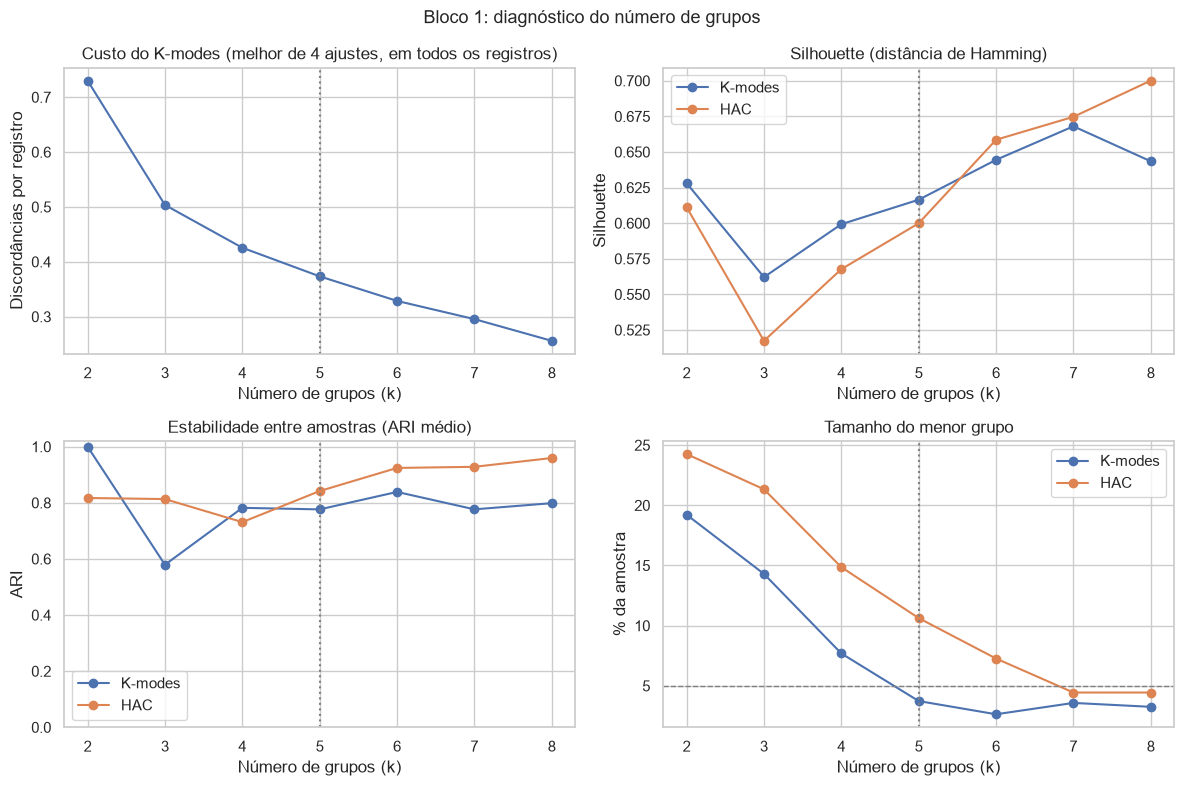

In [6]:
X1 = ind[BLOCO_1].to_numpy()
preparo_1 = preparar_amostras(X1)
diagnostico_1 = diagnosticar(X1, KS_DIAGNOSTICO, preparo_1)
display(diagnostico_1.round(3))
figura_diagnostico(diagnostico_1, 'Bloco 1: diagnóstico do número de grupos', '03_diagnostico_bloco1.png')

## 4.2 Há estrutura além do acaso? Comparação com dados embaralhados

Para *k* = 5, as mesmas medidas são calculadas em dados reais e em dados com cada coluna embaralhada de forma independente (três repetições). Se os grupos reais fossem apenas ruído, os dois resultados seriam parecidos.

In [7]:
calibracao_1 = calibrar_com_embaralhados(X1, K_FINAL, diagnostico_1.loc[K_FINAL])
display(calibracao_1.round(3))
reducao_1 = 100 * (1 - calibracao_1.loc['Custo por registro (K-modes)', 'Dados reais'] / calibracao_1.loc['Custo por registro (K-modes)', 'Embaralhados (média)'])
print(f'Redução do custo do K-modes em relação aos dados embaralhados: {reducao_1:.1f}%')

,Dados reais,Embaralhados (média),Embaralhados (mínimo),Embaralhados (máximo)
Custo por registro (K-modes),0.373,0.492,0.487,0.501
Silhouette K-modes,0.616,0.486,0.445,0.527
Silhouette HAC,0.600,0.479,0.472,0.489
Estabilidade K-modes (ARI),0.776,0.526,0.479,0.564
Estabilidade HAC (ARI),0.842,0.727,0.710,0.746


Redução do custo do K-modes em relação aos dados embaralhados: 24.1%


### Leitura do diagnóstico do bloco 1

- **Não há um *k* claramente melhor.** O custo do K-modes cai de forma contínua (de 0,73 discordâncias por registro em k = 2 para 0,26 em k = 8), sem cotovelo nítido, e o dendrograma tem saltos grandes até k = 4 e queda gradual depois.
- **O silhouette sozinho engana.** Ele é alto (0,6 ou mais) e *sobe* com k, o que é típico de dados 0/1: com poucos perfis possíveis, mais grupos significam grupos mais homogêneos, sem que existam fronteiras naturais. Em dados embaralhados, sem nenhuma associação entre os indicadores, o silhouette ainda chega a cerca de 0,49 (K-modes) e 0,48 (HAC). Só a diferença para esse patamar é informativa.
- **Escolha de k = 5.** Nenhuma métrica decide, então escolhemos o valor em que (a) a estabilidade é razoável nos dois métodos (ARI de 0,78 no K-modes e 0,84 na HAC), (b) o menor grupo é pequeno mas viável (4,9% da amostra no K-modes, na solução final, e 10,6% na HAC) e (c) os perfis têm leitura distinta. Com k = 4 as medidas seriam parecidas (ARI de 0,78 no K-modes e 0,73 na HAC), mas haveria menos resolução entre os perfis intermediários.
- **Há estrutura além do acaso, mas moderada.** Nas cinco medidas, os dados reais ficam fora da faixa (mínimo a máximo) dos dados embaralhados: silhouette de 0,62 contra 0,49 (K-modes) e de 0,60 contra 0,48 (HAC); estabilidade de 0,78 contra 0,53 (K-modes) e de 0,84 contra 0,73 (HAC); custo 24% menor (0,37 contra 0,49 discordâncias por registro). O ganho é real, porém modesto: os perfis são tendências, não categorias bem separadas.

## 4.3 K-modes (k = 5)

Ajustamos o K-modes em todos os registros, com 30 inicializações e escolha da de menor custo. À esquerda, o perfil de cada grupo (% com cada sinal); à direita, a depressão estimada em cada grupo.

,Sinais predominantes (≥ 50% do grupo),n,% da amostra,% da população,Depressão % (IC 95%),Idade mediana,% com 60+ anos
Grupo,,,,,,,
K1,poucos sinais,12141,52.4,59.6,15.6 (14.8-16.4),42.0,22.4
K2,Limitação no trabalho,1136,4.9,5.4,32.0 (28.3-35.6),46.0,30.9
K3,2+ condições crônicas,5670,24.5,20.5,15.8 (14.7-17.0),67.0,70.8
K4,Dor na maioria dos dias + Dificuldade de locomoção + Limitação no trabalho + 2+ condições crônicas,2071,8.9,6.7,35.2 (32.7-37.6),70.0,77.2
K5,Saúde regular ou ruim + Dor na maioria dos dias + Dificuldade de locomoção + Limitação no trabal...,2137,9.2,7.8,59.5 (56.9-62.0),67.0,69.7


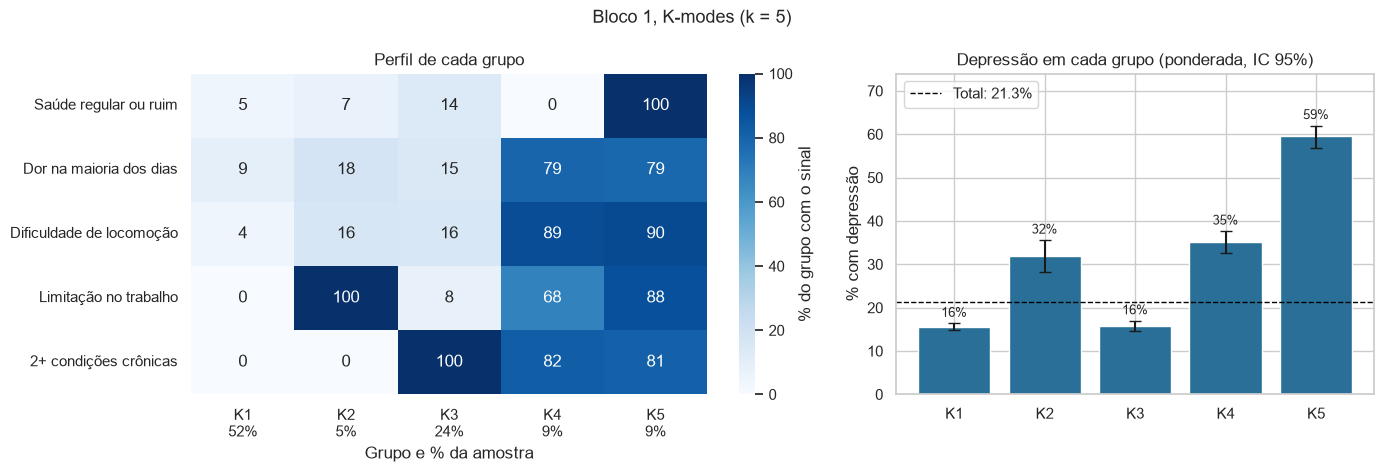

In [8]:
km_1 = kmodes_ajustar(X1, K_FINAL, N_INIT_FINAL, RANDOM_STATE)
rot_km_1 = ordenar_por_carga(X1, km_1.labels_)
display(tabela_grupos(rot_km_1, 'K', ind[BLOCO_1]).round(1))
painel_perfis(rot_km_1, 'K', ind[BLOCO_1], 'Bloco 1, K-modes (k = 5)', '04_kmodes_bloco1.png')

## 4.4 HAC com ligação de Ward (k = 5)

O dendrograma é construído na primeira amostra de 6.000 registros. A figura da direita mostra a altura de cada fusão: um salto grande indica que a fusão juntou grupos bem diferentes.

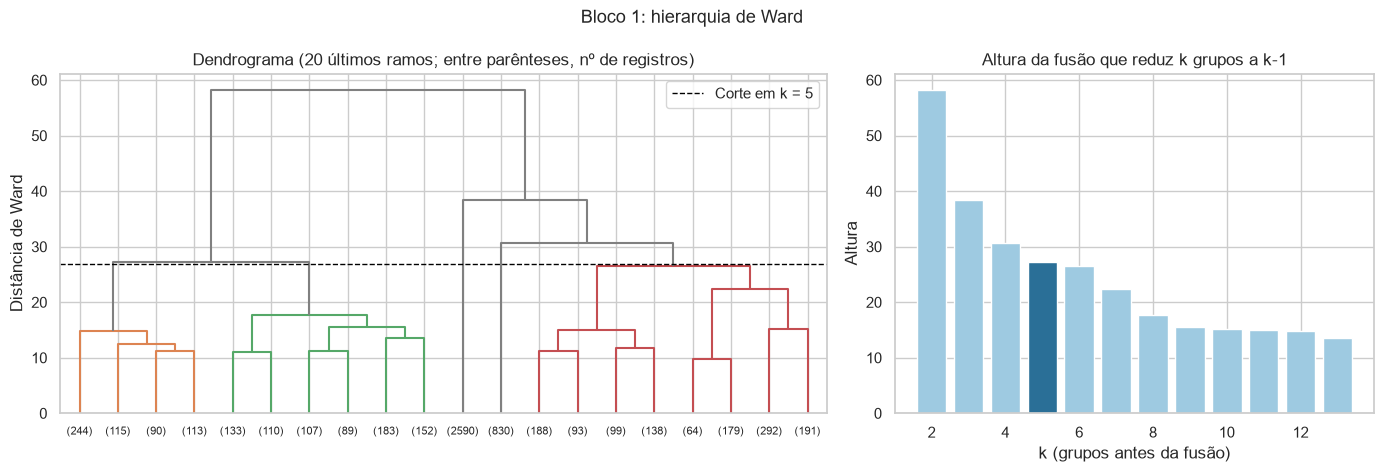

Altura da fusão que reduz k a k-1 grupos (k = 2 a 8): 58.3, 38.4, 30.6, 27.2, 26.6, 22.3, 17.7


,Sinais predominantes (≥ 50% do grupo),n,% da amostra,% da população,Depressão % (IC 95%),Idade mediana,% com 60+ anos
Grupo,,,,,,,
H1,poucos sinais,10495,45.3,52.3,13.5 (12.7-14.3),41.0,20.7
H2,2+ condições crônicas,3819,16.5,14.1,12.1 (10.9-13.3),67.0,68.4
H3,Dor na maioria dos dias,3172,13.7,13.9,33.8 (31.8-35.8),52.0,38.0
H4,Dificuldade de locomoção + 2+ condições crônicas,3208,13.9,10.7,26.4 (24.6-28.4),70.0,75.8
H5,Saúde regular ou ruim + Dor na maioria dos dias + Dificuldade de locomoção + Limitação no trabal...,2461,10.6,9.0,55.2 (52.8-57.5),67.0,71.0


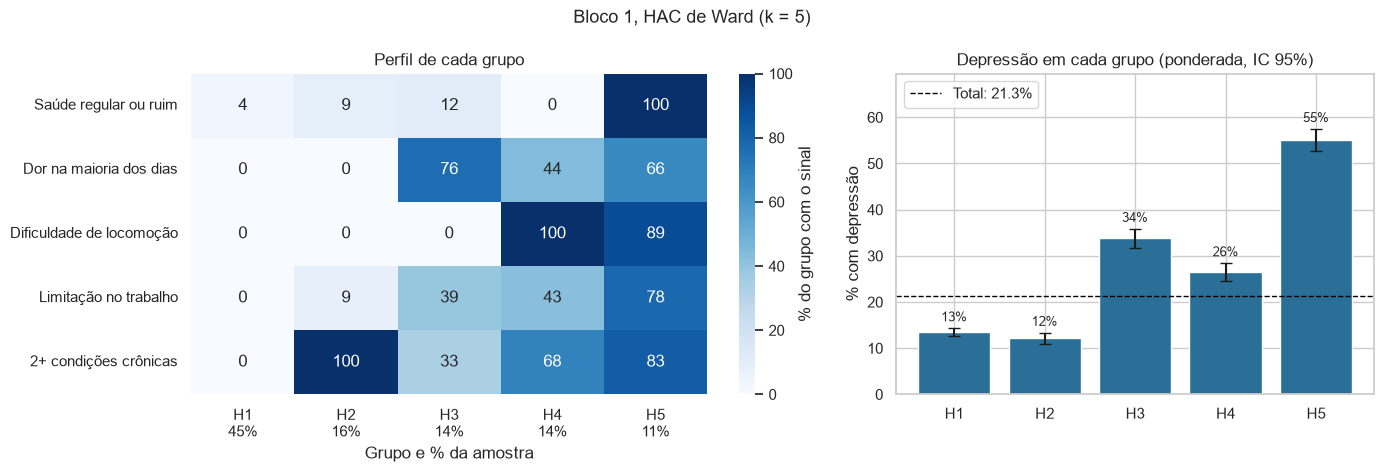

In [9]:
amostras_1, arvores_1, _ = preparo_1
figura_dendrograma(arvores_1[0], K_FINAL, 'Bloco 1: hierarquia de Ward', '05_dendrograma_bloco1.png')
rot_h_1 = ordenar_por_carga(X1, hac_rotulos(arvores_1[0], X1, amostras_1[0], K_FINAL))
display(tabela_grupos(rot_h_1, 'H', ind[BLOCO_1]).round(1))
painel_perfis(rot_h_1, 'H', ind[BLOCO_1], 'Bloco 1, HAC de Ward (k = 5)', '06_hac_bloco1.png')

## 4.5 K-modes e HAC chegam aos mesmos grupos?

A matriz mostra, para cada grupo do K-modes, que parcela cai em cada grupo da HAC (cada linha soma 100%). Como os grupos são numerados do menor para o maior número de sinais, concordância alta aparece na diagonal.

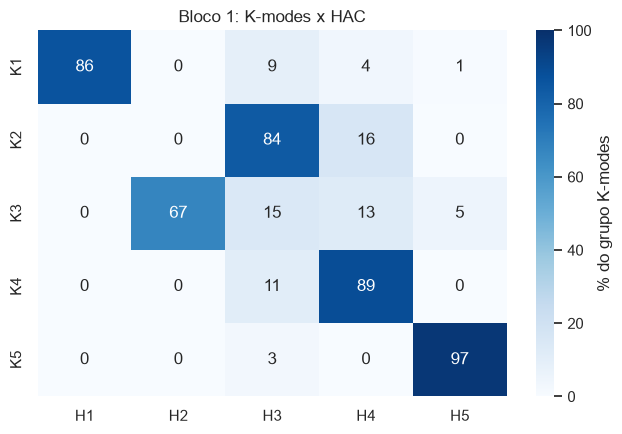

ARI entre K-modes e HAC: 0.71 | informação mútua normalizada: 0.65


In [10]:
comparar_metodos(rot_km_1, rot_h_1, 'Bloco 1: K-modes x HAC', '07_kmodes_x_hac_bloco1.png')

## 4.6 Os grupos dizem mais do que a simples contagem de sinais?

Se os grupos apenas ordenassem as pessoas pelo número de sinais, uma contagem de 0 a 5 explicaria tanto quanto eles. A comparação usa o V de Cramér entre cada partição e a depressão.

In [11]:
grupos_vs_contagem(ind[BLOCO_1], {'K-modes': rot_km_1, 'HAC': rot_h_1})

,n,Depressão % (ponderada)
Nº de sinais no bloco,,
0,10125,12.8
1,5637,19.8
2,2943,25.8
3,1964,36.0
4,1456,50.6
5,1030,66.5


V de Cramér com a depressão: Nº de sinais (contagem simples): 0.331 | Grupos K-modes: 0.325 | Grupos HAC: 0.328


### Leitura do bloco 1

**Cinco perfis reconhecíveis, e os dois métodos concordam** (ARI = 0,71: cada grupo do K-modes cai, em sua maior parte, em um único grupo da HAC).

| Perfil (K-modes) | % da amostra | Depressão | Grupo correspondente na HAC |
|---|---|---|---|
| K1: poucos sinais | 52,4% | 15,6% | H1: 45,3% da amostra, 13,5% |
| K3: 2+ condições crônicas, sem os demais sinais | 24,5% | 15,8% | H2: 16,5%, 12,1% |
| K2: limitação no trabalho | 4,9% | 32,0% | H3 (dor na maioria dos dias): 13,7%, 33,8% |
| K4: dor, mobilidade, limitação e condições, sem saúde regular ou ruim | 8,9% | 35,2% | H4 (mobilidade e condições): 13,9%, 26,4% |
| K5: todos os sinais | 9,2% | 59,5% | H5: 10,6%, 55,2% |

- **A depressão sobe com a carga de sinais funcionais, em três patamares:** cerca de 12% a 16% (poucos sinais ou só condições crônicas), 26% a 35% (dor, limitação ou mobilidade reduzida) e 55% a 60% (todos os sinais). K2 e K4 têm intervalos de confiança que se sobrepõem.
- **Doenças crônicas sozinhas não aumentam a depressão no total** (K3 com 15,8% e H2 com 12,1%, iguais ou abaixo de K1 e H1), **mas isso é efeito da idade.** Esses grupos são muito mais velhos (mediana de 67 anos contra 41 a 42; 68% a 71% com 60+ contra 21% a 22%), e a depressão cai com a idade. A seção 7.1 mostra que, dentro de cada faixa etária, K3 tem cerca do dobro da depressão de K1.
- **Quantos sinais contra quais sinais.** A contagem simples de sinais (0 a 5) tem V = 0,331 com a depressão, igual aos grupos (0,325 no K-modes e 0,328 na HAC): os grupos **não explicam mais** que a contagem, que vai de 12,8% (nenhum sinal) a 66,5% (cinco sinais). O que os grupos acrescentam é a informação de *quais* sinais pesam: em grupos definidos por um único sinal predominante, a limitação no trabalho (K2: 32,0%) leva o dobro da depressão de ter só 2+ condições crônicas (K3: 15,8%).
- **É um gradiente, não categorias naturais.** O dendrograma não tem salto nítido depois de k = 4, e o K-modes move um pouco os limites entre amostras (ARI 0,78). Os perfis servem para descrever a população, mas a fronteira entre "poucos sinais" e "um sinal" é arbitrária.

# 5. Bloco 2: contexto psicossocial e financeiro

Indicadores: solidão, pouco suporte social, dificuldade cognitiva, preocupação financeira com a saúde e renda abaixo de duas vezes a linha de pobreza. A sequência de análises é a mesma do bloco 1.

## 5.1 Diagnóstico para k = 2 a 8 e comparação com dados embaralhados

,Custo por registro (K-modes),Silhouette K-modes,Silhouette HAC,Estabilidade K-modes (ARI),Estabilidade HAC (ARI),Menor grupo K-modes (%),Menor grupo HAC (%),ARI K-modes x HAC
k,,,,,,,,
2,0.992,0.437,0.428,0.353,0.609,41.550,33.081,0.054
3,0.782,0.412,0.437,0.696,0.541,23.718,15.988,0.381
4,0.664,0.460,0.319,0.472,0.535,12.796,15.988,0.392
5,0.610,0.412,0.418,0.545,0.719,7.467,12.831,0.423
6,0.511,0.450,0.485,0.653,0.788,5.295,10.317,0.435
7,0.442,0.517,0.524,0.656,0.801,3.226,8.586,0.627
8,0.428,0.551,0.564,0.582,0.822,2.742,4.967,0.642


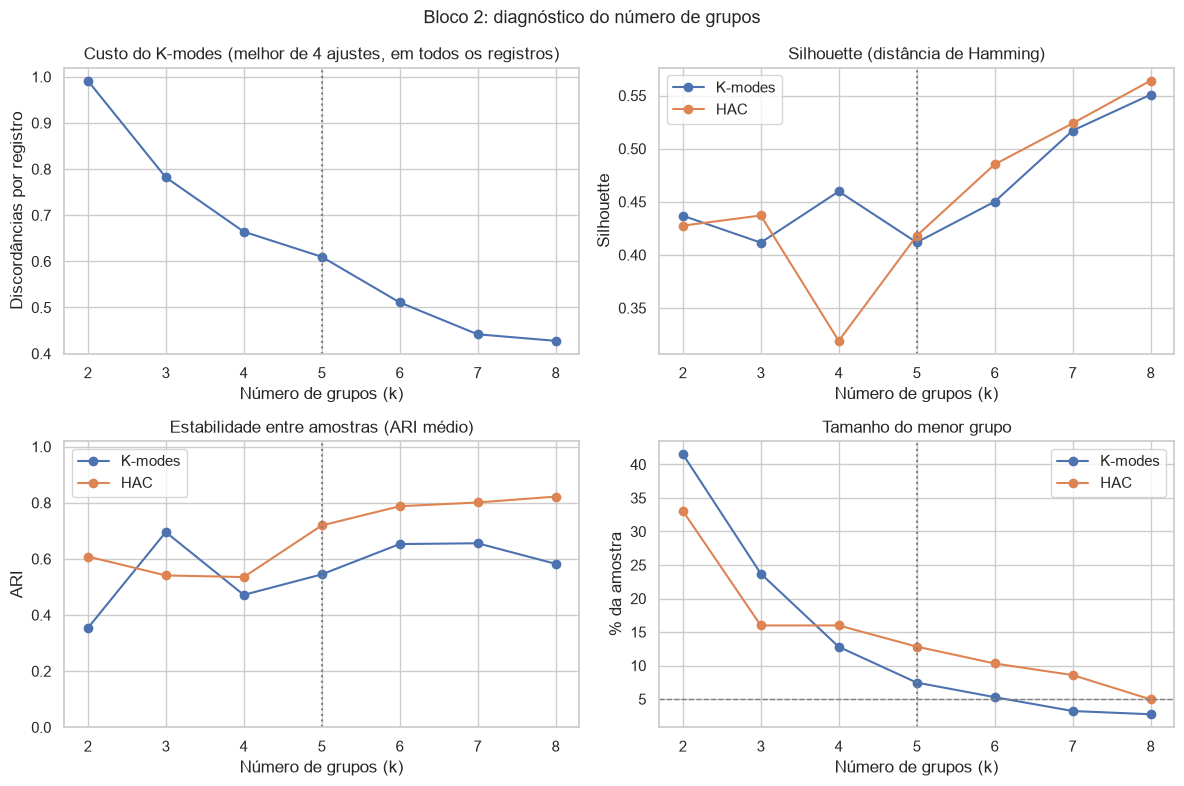

,Dados reais,Embaralhados (média),Embaralhados (mínimo),Embaralhados (máximo)
Custo por registro (K-modes),0.610,0.623,0.611,0.644
Silhouette K-modes,0.412,0.433,0.405,0.485
Silhouette HAC,0.418,0.441,0.429,0.454
Estabilidade K-modes (ARI),0.545,0.483,0.355,0.625
Estabilidade HAC (ARI),0.719,0.867,0.837,0.884


Redução do custo do K-modes em relação aos dados embaralhados: 2.0%


In [12]:
X2 = ind[BLOCO_2].to_numpy()
preparo_2 = preparar_amostras(X2)
diagnostico_2 = diagnosticar(X2, KS_DIAGNOSTICO, preparo_2)
display(diagnostico_2.round(3))
figura_diagnostico(diagnostico_2, 'Bloco 2: diagnóstico do número de grupos', '08_diagnostico_bloco2.png')

calibracao_2 = calibrar_com_embaralhados(X2, K_FINAL, diagnostico_2.loc[K_FINAL])
display(calibracao_2.round(3))
reducao_2 = 100 * (1 - calibracao_2.loc['Custo por registro (K-modes)', 'Dados reais'] / calibracao_2.loc['Custo por registro (K-modes)', 'Embaralhados (média)'])
print(f'Redução do custo do K-modes em relação aos dados embaralhados: {reducao_2:.1f}%')

### Leitura do diagnóstico do bloco 2

- **Não há estrutura de grupos acima do acaso.** Nenhuma medida dos dados reais se destaca dos dados embaralhados: o custo do K-modes é só 2% menor (0,61 contra 0,62, no limite inferior da faixa embaralhada), os silhouettes são 0,41 (K-modes) e 0,42 (HAC) contra 0,43 e 0,44, e a estabilidade do K-modes (0,55) cai na faixa dos embaralhados (0,355 a 0,625).
- **Estabilidade alta não prova estrutura:** a da HAC (0,72) é até **menor** que a dos dados embaralhados (0,87).
- Como os sinais do bloco 2 quase não andam juntos (seção 2.1), qualquer partição acaba separando pessoas por um sinal de cada vez.

## 5.2 K-modes (k = 5)

,Sinais predominantes (≥ 50% do grupo),n,% da amostra,% da população,Depressão % (IC 95%),Idade mediana,% com 60+ anos
Grupo,,,,,,,
K1,poucos sinais,7942,34.3,33.6,6.7 (6.0-7.3),57.0,46.3
K2,Renda < 2x a pobreza,2050,8.9,8.8,12.0 (10.3-13.6),61.0,52.6
K3,Preocupação financeira,5946,25.7,28.5,14.4 (13.5-15.5),48.0,31.5
K4,Dificuldade cognitiva,3969,17.1,16.0,35.1 (33.3-37.0),64.0,57.2
K5,Solidão (às vezes ou mais) + Pouco suporte social + Dificuldade cognitiva + Preocupação financeira,3248,14.0,13.1,63.0 (61.0-65.0),53.0,39.4


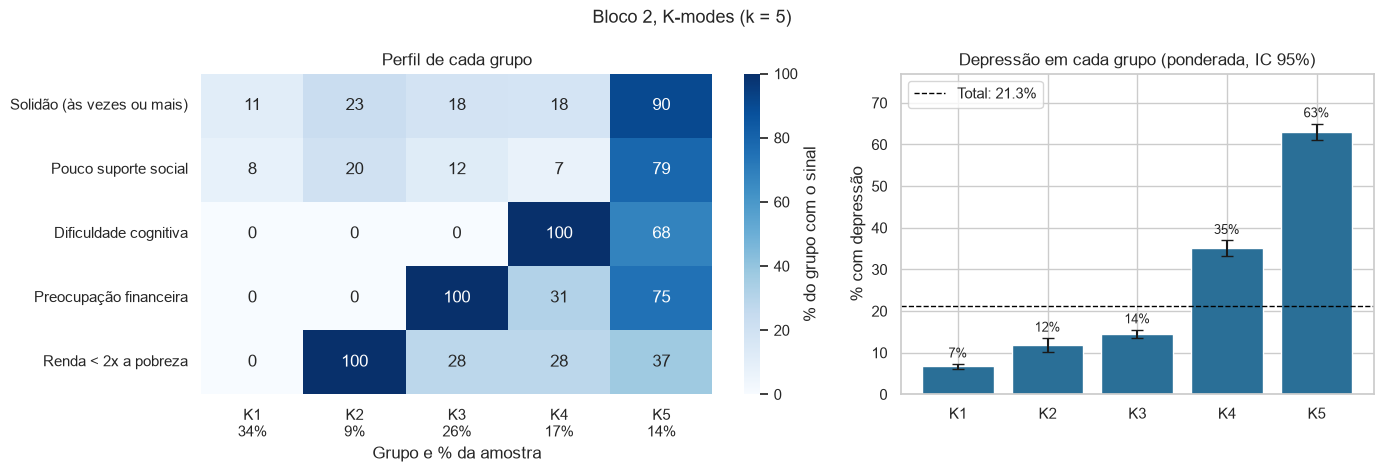

In [13]:
km_2 = kmodes_ajustar(X2, K_FINAL, N_INIT_FINAL, RANDOM_STATE)
rot_km_2 = ordenar_por_carga(X2, km_2.labels_)
display(tabela_grupos(rot_km_2, 'K', ind[BLOCO_2]).round(1))
painel_perfis(rot_km_2, 'K', ind[BLOCO_2], 'Bloco 2, K-modes (k = 5)', '09_kmodes_bloco2.png')

## 5.3 HAC com ligação de Ward (k = 5)

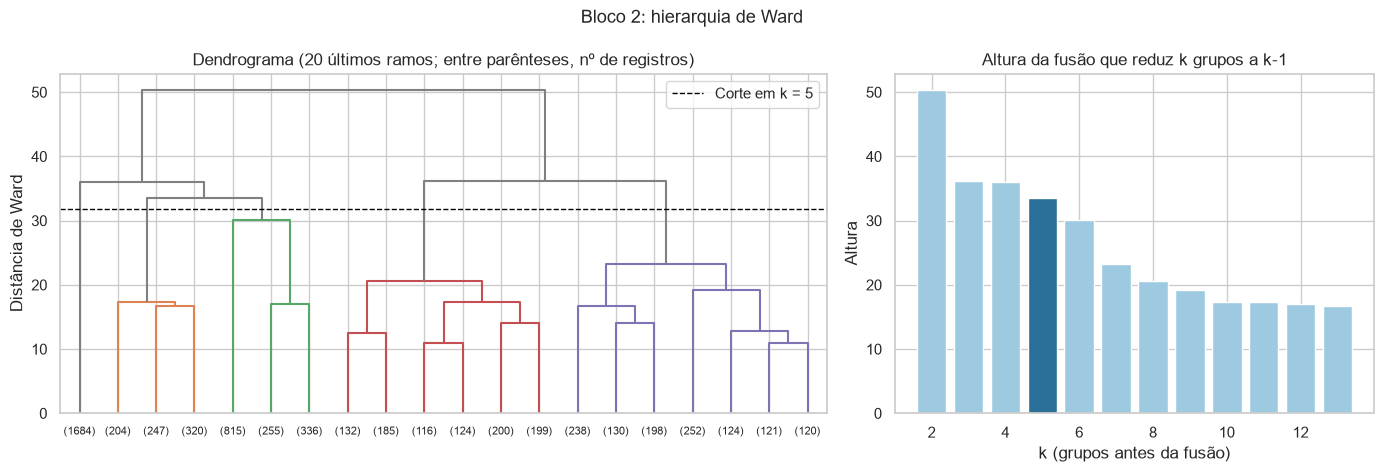

Altura da fusão que reduz k a k-1 grupos (k = 2 a 8): 50.4, 36.1, 35.9, 33.5, 30.1, 23.2, 20.6


,Sinais predominantes (≥ 50% do grupo),n,% da amostra,% da população,Depressão % (IC 95%),Idade mediana,% com 60+ anos
Grupo,,,,,,,
H1,poucos sinais,6408,27.7,27.5,4.7 (4.1-5.2),57.0,45.5
H2,Preocupação financeira,5481,23.7,26.3,9.8 (8.9-10.8),50.0,35.9
H3,Dificuldade cognitiva,2971,12.8,12.2,29.8 (27.7-31.8),63.0,55.6
H4,Solidão (às vezes ou mais),3702,16.0,15.2,40.1 (38.1-42.0),56.0,45.4
H5,Solidão (às vezes ou mais) + Pouco suporte social + Preocupação financeira,4593,19.8,18.7,40.8 (39.1-42.5),55.0,42.6


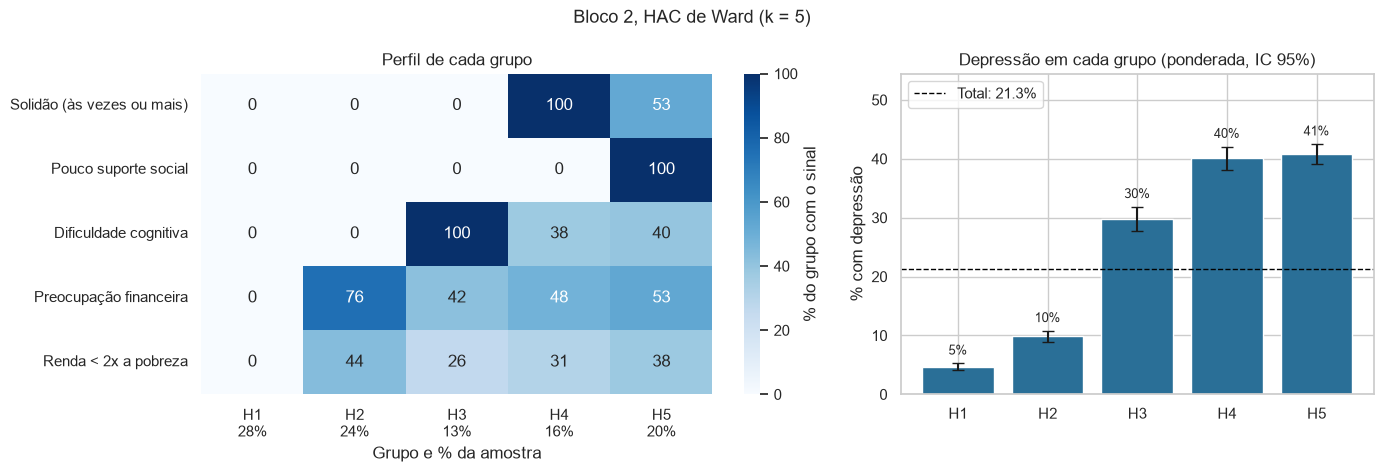

In [14]:
amostras_2, arvores_2, _ = preparo_2
figura_dendrograma(arvores_2[0], K_FINAL, 'Bloco 2: hierarquia de Ward', '10_dendrograma_bloco2.png')
rot_h_2 = ordenar_por_carga(X2, hac_rotulos(arvores_2[0], X2, amostras_2[0], K_FINAL))
display(tabela_grupos(rot_h_2, 'H', ind[BLOCO_2]).round(1))
painel_perfis(rot_h_2, 'H', ind[BLOCO_2], 'Bloco 2, HAC de Ward (k = 5)', '11_hac_bloco2.png')

## 5.4 K-modes x HAC e comparação com a contagem de sinais

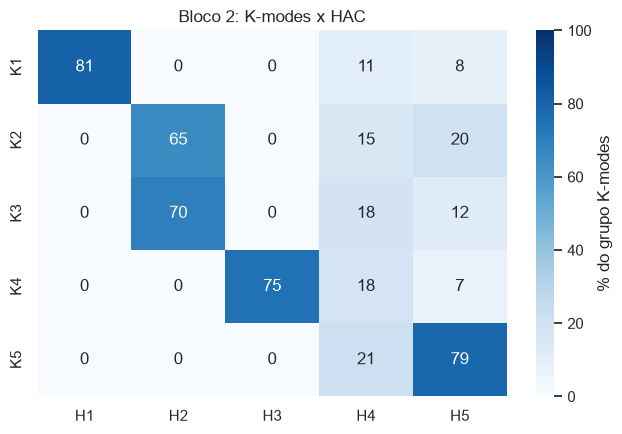

ARI entre K-modes e HAC: 0.55 | informação mútua normalizada: 0.57


,n,Depressão % (ponderada)
Nº de sinais no bloco,,
0,6408,4.7
1,7276,12.5
2,5042,27.1
3,2844,44.8
4,1233,70.2
5,352,83.8


V de Cramér com a depressão: Nº de sinais (contagem simples): 0.454 | Grupos K-modes: 0.444 | Grupos HAC: 0.370


In [15]:
comparar_metodos(rot_km_2, rot_h_2, 'Bloco 2: K-modes x HAC', '12_kmodes_x_hac_bloco2.png')
grupos_vs_contagem(ind[BLOCO_2], {'K-modes': rot_km_2, 'HAC': rot_h_2})

### Leitura do bloco 2

- **Os grupos são quase "um sinal de cada vez".** No K-modes, K2, K3 e K4 são definidos cada um por um único sinal (renda baixa, preocupação financeira e dificuldade cognitiva), K1 reúne quem tem poucos sinais e K5 junta solidão, pouco suporte, dificuldade cognitiva e preocupação financeira. A HAC faz algo parecido. É o que se espera de sinais quase independentes.
- **K-modes e HAC concordam menos que no bloco 1** (ARI 0,55, contra 0,71): a partição depende do método, outro indício de que não há grupos naturais.
- **A contagem de sinais é mais informativa que os grupos:** V = 0,454 para a contagem, contra 0,444 (K-modes) e 0,370 (HAC). A depressão passa de 4,7% (nenhum sinal) para 12,5% (um), 27,1% (dois), 44,8% (três), 70,2% (quatro) e 83,8% (cinco; apenas 352 registros). Na prática, este bloco é **um gradiente de acúmulo de sinais**, não um conjunto de tipos de pessoas.
- **Depressão por grupo:** de 6,7% (K1) a 63,0% (K5) no K-modes, e de 4,7% (H1) a 40,8% (H5) na HAC.
- **Ressalva:** solidão e dificuldade cognitiva, que mais pesam aqui, são os sinais mais próximos de sintomas depressivos (isolamento e dificuldade de concentração fazem parte do quadro). Parte deste gradiente pode ser o próprio quadro depressivo. A seção 7.2 retira os dois.

# 6. Os dois blocos juntos

Como o bloco 2 funciona mais como um contador de sinais do que como grupos distintos, cruzamos os **grupos físicos do K-modes** com o **número de sinais psicossociais e financeiros** (0, 1, 2 ou 3+). Cada célula mostra a depressão estimada (ponderada) e o número de registros. Células com menos de 50 registros ficam em branco.

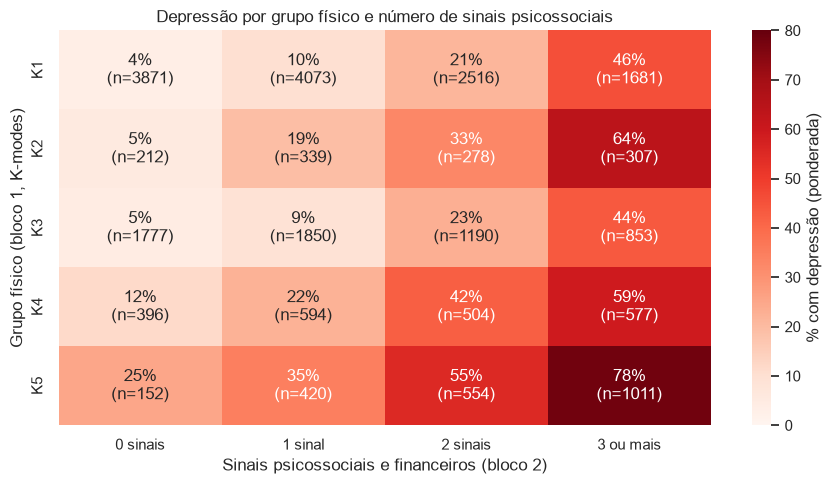

In [16]:
sinais_bloco_2 = ind[BLOCO_2].sum(axis=1).clip(upper=3).to_numpy()
ROTULOS_SINAIS = ['0 sinais', '1 sinal', '2 sinais', '3 ou mais']

prevalencias = np.full((K_FINAL, 4), np.nan)
contagens = np.zeros((K_FINAL, 4), dtype=int)
for g in range(K_FINAL):
    for s in range(4):
        m = (rot_km_1 == g) & (sinais_bloco_2 == s)
        contagens[g, s] = m.sum()
        if m.sum() >= MIN_REGISTROS_CELULA:
            prevalencias[g, s] = 100 * np.average(y[m], weights=w[m])

anotacoes = np.where(np.isnan(prevalencias), '', [[f'{p:.0f}%\n(n={n})' for p, n in zip(lp, ln)] for lp, ln in zip(prevalencias, contagens)])
plt.figure(figsize=(9, 5))
sns.heatmap(pd.DataFrame(prevalencias, index=[f'K{g + 1}' for g in range(K_FINAL)], columns=ROTULOS_SINAIS),
            annot=anotacoes, fmt='', cmap='Reds', vmin=0, vmax=80, cbar_kws={'label': '% com depressão (ponderada)'})
plt.xlabel('Sinais psicossociais e financeiros (bloco 2)')
plt.ylabel('Grupo físico (bloco 1, K-modes)')
plt.title('Depressão por grupo físico e número de sinais psicossociais')
plt.tight_layout()
salvar_figura('13_cruzamento_blocos.png')
plt.show()

### Leitura

- **A depressão cresce com os sinais psicossociais em todos os perfis físicos:** em K1, de 4% (nenhum sinal) a 46% (três ou mais); em K5, de 25% a 78%.
- **O perfil físico importa mesmo com a mesma carga psicossocial.** Sem nenhum sinal psicossocial, K1 a K3 ficam entre 4% e 5%, K4 em 12% e K5 em 25%. Com três ou mais sinais, K1 e K3 ficam em 44% a 46%, K4 em 59%, K2 em 64% e K5 em 78%.
- **A combinação de maior risco é carga física alta com três ou mais sinais psicossociais: 78% (n = 1.011).** A de menor risco é "poucos sinais" ou "só condições crônicas" sem nenhum sinal psicossocial: 4% a 5%.
- Os dois eixos somam efeitos: a carga física não explica tudo (K1 chega a 46% com três sinais psicossociais), nem a psicossocial explica tudo (K5 já tem 25% sem nenhum).

# 7. Checagens de robustez

## 7.1 O gradiente aparece dentro de cada faixa etária?

A idade se relaciona com quase tudo (condições crônicas, renda, solidão) e a depressão é menos frequente entre idosos. Para saber se os grupos físicos refletem apenas a idade, calculamos a depressão de cada grupo do K-modes **dentro de cada faixa etária**.

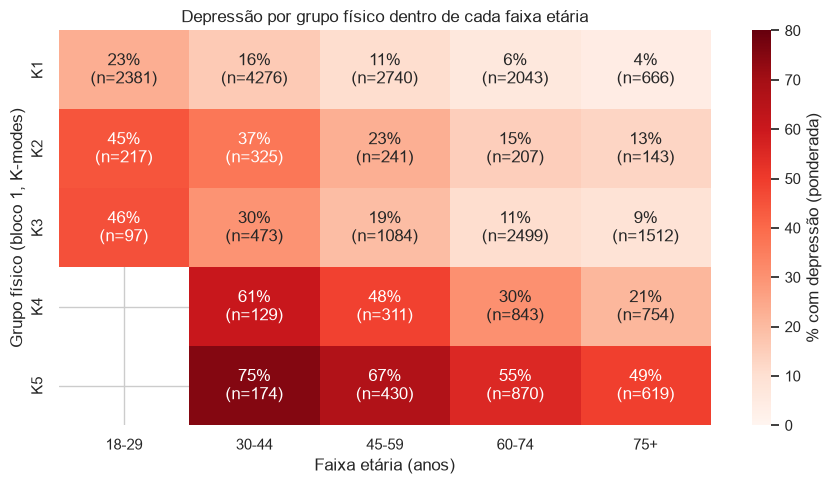

In [17]:
faixas = ['18-29', '30-44', '45-59', '60-74', '75+']
prev_faixa = np.full((K_FINAL, len(faixas)), np.nan)
n_faixa = np.zeros((K_FINAL, len(faixas)), dtype=int)
for g in range(K_FINAL):
    for j, faixa in enumerate(faixas):
        m = (rot_km_1 == g) & (faixa_etaria == faixa).to_numpy()
        n_faixa[g, j] = m.sum()
        if m.sum() >= MIN_REGISTROS_CELULA:
            prev_faixa[g, j] = 100 * np.average(y[m], weights=w[m])

anotacoes = np.where(np.isnan(prev_faixa), '', [[f'{p:.0f}%\n(n={n})' for p, n in zip(lp, ln)] for lp, ln in zip(prev_faixa, n_faixa)])
plt.figure(figsize=(9, 5))
sns.heatmap(pd.DataFrame(prev_faixa, index=[f'K{g + 1}' for g in range(K_FINAL)], columns=faixas),
            annot=anotacoes, fmt='', cmap='Reds', vmin=0, vmax=80, cbar_kws={'label': '% com depressão (ponderada)'})
plt.xlabel('Faixa etária (anos)')
plt.ylabel('Grupo físico (bloco 1, K-modes)')
plt.title('Depressão por grupo físico dentro de cada faixa etária')
plt.tight_layout()
salvar_figura('14_depressao_por_faixa_etaria.png')
plt.show()

### Leitura

- **A ordem dos grupos se mantém em todas as faixas de 30 anos ou mais:** K1 < K3 < K2 < K4 < K5. Entre 60 e 74 anos, por exemplo, a depressão é de 6% (K1), 11% (K3), 15% (K2), 30% (K4) e 55% (K5). O gradiente físico, portanto, não é só efeito da idade.
- **A idade explica por que as doenças crônicas pareciam "neutras".** K3 (só condições crônicas) e K1 (poucos sinais) têm a mesma depressão no total (15,8% e 15,6%), mas K3 é bem mais velho (mediana de 67 anos contra 42). Dentro de cada faixa, K3 tem cerca do dobro da depressão de K1, por exemplo 19% contra 11% entre 45 e 59 anos. Isso é coerente com a análise exploratória, que já indicava que a idade mascara parte da relação das doenças crônicas com a depressão.
- Em todos os grupos a depressão **cai com a idade** (em K1, de 23% aos 18 a 29 anos para 4% a partir dos 75). Células com menos de 50 registros (K4 e K5 entre 18 e 29 anos) ficam em branco.

## 7.2 O que muda com outras escolhas de variáveis?

Repetimos o K-modes (k = 5) em variantes do desenho. Para cada uma: estabilidade (ARI entre amostras), silhouette, faixa de depressão entre os grupos e o V de Cramér entre os grupos e a depressão.

| Variante | O que testa |
|---|---|
| Bloco 1 e bloco 2 | referência (as soluções das seções 4 e 5) |
| Bloco 2 sem solidão e cognição | se o gradiente depende dos sinais mais próximos de sintomas depressivos |
| Bloco 1 com níveis completos | se transformar as variáveis em indicadores 0/1 cria ou destrói a estrutura |
| Dez indicadores juntos | se agrupar tudo de uma vez seria melhor que separar em blocos |
| Controle negativo | variáveis sem relação com a depressão (região, urbano/rural, exame de vista, câncer, plano público): os grupos não deveriam diferir em depressão |

In [18]:
NIVEIS_BLOCO_1 = pd.DataFrame({
    'Saúde geral (4 níveis)': base['AUTOAVALIACAO_SAUDE_GERAL'].map({1: 1, 2: 1, 3: 2, 4: 3, 5: 4}),
    'Dor crônica (4 níveis)': base['DOR_CRONICA'],
    'Locomoção (3 níveis)': base['DIFICULDADE_LOCOMOCAO'].map({1: 1, 2: 2, 3: 3, 4: 3}),
    'Limitação no trabalho (2 níveis)': base['LIMITACAO_TRABALHO_POR_SAUDE'],
    'Condições crônicas (4 níveis)': (base[CONDICOES] == 1).sum(axis=1).clip(upper=3) + 1,
})
CONTROLE = ['REGIAO_GEOGRAFICA', 'CLASSIFICACAO_URBANO_RURAL', 'VISITAS_EXAME_VISTA_12M', 'TEVE_CANCER', 'PLANO_PUBLICO']
assert not set(CONTROLE) & set(COLUNAS_SINTOMAS)
controle_valido = (base[CONTROLE] != -1).all(axis=1).to_numpy()

VARIANTES = {
    'Bloco 1 (indicadores)': ind[BLOCO_1],
    'Bloco 2 (indicadores)': ind[BLOCO_2],
    'Bloco 2 sem solidão e cognição': ind[['Pouco suporte social', 'Preocupação financeira', 'Renda < 2x a pobreza']],
    'Bloco 1 com níveis completos': NIVEIS_BLOCO_1,
    'Dez indicadores juntos': ind,
}


def resumir_variante(nome, tabela, y_local, w_local):
    X = tabela.to_numpy()
    amostras = sortear_amostras(len(X))
    rot_amostras = [kmodes_ajustar(X[a], K_FINAL, N_INIT_DIAGNOSTICO, RANDOM_STATE + i).predict(X) for i, a in enumerate(amostras)]
    modelo = kmodes_ajustar(X, K_FINAL, N_INIT_FINAL // 3, RANDOM_STATE)
    idx = np.random.default_rng(RANDOM_STATE).choice(len(X), TAMANHO_SILHOUETTE, replace=False)
    prev = np.array([np.average(y_local[modelo.labels_ == c], weights=w_local[modelo.labels_ == c]) for c in range(K_FINAL)])
    return {
        'Variante': nome,
        'Variáveis': X.shape[1],
        'Estabilidade (ARI)': media_ari(rot_amostras),
        'Silhouette': silhouette_score(X[idx], modelo.labels_[idx], metric='hamming'),
        'Depressão mín-máx (%)': f'{100 * prev.min():.0f}-{100 * prev.max():.0f}',
        'V grupos x depressão': cramers_v(pd.crosstab(modelo.labels_, y_local)),
    }


resumo_variantes = [resumir_variante(nome, tabela, y, w) for nome, tabela in VARIANTES.items()]
resumo_variantes.append(resumir_variante('Controle negativo (5 variáveis sem relação com depressão)',
                                         base.loc[controle_valido, CONTROLE], y[controle_valido], w[controle_valido]))
display(pd.DataFrame(resumo_variantes).set_index('Variante').round(3))

,Variáveis,Estabilidade (ARI),Silhouette,Depressão mín-máx (%),V grupos x depressão
Variante,,,,,
Bloco 1 (indicadores),5,0.776,0.623,16-59,0.325
Bloco 2 (indicadores),5,0.545,0.490,9-68,0.398
Bloco 2 sem solidão e cognição,3,0.816,0.814,11-34,0.222
Bloco 1 com níveis completos,5,0.381,0.174,11-49,0.304
Dez indicadores juntos,10,0.551,0.292,11-69,0.381
Controle negativo (5 variáveis sem relação com depressão),5,0.279,0.197,18-23,0.046


### Leitura das variantes

- **Níveis completos em vez de indicadores (bloco 1):** a estabilidade cai de 0,78 para 0,38 e o silhouette de 0,62 para 0,17, mas o gradiente de depressão (11% a 49%) e a associação com ela (V = 0,304 contra 0,325) permanecem. A **informação** continua lá; a **separação em grupos** é que depende em parte de transformar as variáveis em sinais 0/1. Com os níveis completos, os grupos são cortes de um contínuo.
- **Dez indicadores juntos:** a estabilidade (0,55) é menor que a do bloco 1 sozinho (0,78) e os grupos ficam mais difíceis de ler. O V com a depressão (0,38) é parecido com o do bloco 2 (0,40). Separar em blocos foi uma boa escolha.
- **Bloco 2 sem solidão e cognição:** o gradiente persiste, mas diminui: a depressão varia de 11% a 34% (contra 9% a 68% com os dois sinais) e o V cai de 0,40 para 0,22. Pouco suporte social, preocupação financeira e renda baixa ainda separam grupos, mas o contraste mais forte do bloco 2 depende dos dois sinais mais próximos de sintomas depressivos. O silhouette (0,81) não é comparável: com três indicadores existem só 8 perfis possíveis.
- **Controle negativo:** grupos formados com cinco variáveis sem relação com a depressão (região, urbano/rural, exame de vista, câncer e plano público) quase não diferem em depressão (18% a 23%; V = 0,05). O gradiente dos blocos vem, portanto, **do conteúdo das variáveis**, e não do ato de agrupar. Isso não elimina a circularidade da seleção (seção 1.2): as variáveis dos blocos foram escolhidas justamente por se associarem à depressão.

# 8. Conclusão

## Resumo dos achados

| Pergunta | Bloco 1: saúde física e funcionalidade | Bloco 2: contexto psicossocial e financeiro |
|---|---|---|
| Há estrutura de grupos acima do acaso? | **Sim, moderada.** Estabilidade do K-modes de 0,78 (0,53 nos dados embaralhados), silhouette de 0,62 (0,49) e custo 24% menor | **Não.** Nenhuma medida se destaca dos dados embaralhados (o custo é só 2% menor) |
| K-modes e HAC concordam? | Bastante (ARI = 0,71) | Em parte (ARI = 0,55) |
| Os grupos explicam mais que a contagem simples de sinais? | Não (V = 0,33 nos três casos) | Não (V = 0,44 e 0,37 contra 0,45 da contagem) |
| Depressão entre os grupos do K-modes | de 15,6% a 59,5% | de 6,7% a 63,0% |
| Como ler | Cinco perfis recorrentes ao longo de um gradiente de carga funcional | Um gradiente de acúmulo de sinais, sem tipos distintos |

## O que aprendemos

1. **Não encontramos "nada", mas também não encontramos grupos naturais bem separados.** No bloco físico-funcional aparecem cinco perfis reconhecíveis, nos dois métodos, estáveis e acima do que o acaso produz. São moderados: a hierarquia não tem um corte nítido e as fronteiras mudam um pouco entre amostras. Eles resumem um gradiente de carga funcional.
2. **O que separa a depressão é a dor e a limitação funcional, e não as doenças crônicas isoladas.** Perfis com poucos sinais ou só com condições crônicas têm cerca de 12% a 16% de depressão; com dor, limitação ou mobilidade reduzida, 26% a 35%; com todos os sinais (saúde regular ou ruim, dor, mobilidade, limitação e condições), 55% a 60%. As condições crônicas sozinhas parecem neutras no total, mas isso vem da idade: dentro de cada faixa etária, elas têm cerca do dobro da depressão de quem tem poucos sinais.
3. **O contexto psicossocial é o contraste mais forte, mas não forma grupos.** Solidão, pouco suporte, dificuldade cognitiva, preocupação financeira e renda baixa se somam: a depressão vai de 4,7% (nenhum sinal) a 83,8% (cinco sinais). Solidão e dificuldade cognitiva se sobrepõem a sintomas depressivos; sem elas, o gradiente diminui (V de 0,40 para 0,22; depressão de 11% a 34%).
4. **Os dois blocos somam efeitos.** Carga física alta com três ou mais sinais psicossociais chega a 78% de depressão; poucos sinais físicos e nenhum sinal psicossocial ficam em 4% a 5%.
5. **K-modes e HAC concordam onde há estrutura e divergem onde não há.** No bloco 1 eles chegam a grupos bem parecidos (ARI = 0,71); no bloco 2 divergem mais (ARI = 0,55). Isso funciona como um teste prático de que os grupos do bloco 1 são mais do que um artefato do algoritmo.

## Sobre a hipótese do projeto

Os resultados **apoiam** a hipótese: sinais físicos e funcionais (dor, mobilidade, limitação no trabalho e saúde autoavaliada), sem nenhum sintoma de saúde mental, separam perfis com cerca de 13% a 60% de depressão, e o gradiente se mantém dentro de cada faixa etária. Duas ressalvas:

- as variáveis foram escolhidas por se associarem à depressão, então essa diferença é esperada. O controle negativo (18% a 23% de depressão em grupos formados com variáveis sem relação) mostra que ela vem do conteúdo das variáveis, mas não torna a descoberta independente;
- saúde autoavaliada, dor e limitação são autorrelatos e podem refletir também o sofrimento psicológico, não só a condição física.

## Limitações

- **Estudo transversal:** mostra associação, não causalidade nem direção. A depressão também pode aumentar dor, solidão e limitação.
- **Os cortes dos indicadores são escolhas.** Com os níveis completos, os grupos perdem estabilidade (ARI de 0,78 para 0,38).
- **Os algoritmos têm limites:** o K-modes depende da inicialização (ARI de 0,78 entre amostras no bloco 1) e a HAC é montada em amostras de 6.000 registros e estendida aos demais pelo centroide mais próximo.
- **Circularidade e sobreposição:** a seleção usou a associação com a depressão, e solidão e dificuldade cognitiva se sobrepõem a sintomas depressivos.
- **Incerteza:** o IC por bootstrap ignora o desenho amostral complexo da pesquisa. O peso amostral não entra na formação dos grupos. Só registros completos (98%) foram usados.
- **O silhouette em dados 0/1 é inflado** e só foi interpretado junto da comparação com dados embaralhados.

## Próximos passos

- Repetir a análise com outro ano do NHIS para ver se os cinco perfis físico-funcionais se repetem.
- Testar uma análise de classes latentes, modelo probabilístico para variáveis categóricas que oferece um critério de informação (BIC) para escolher o número de grupos.
- Avaliar o recall dos modelos supervisionados dentro de cada perfil físico, para ver em quais perfis eles deixam mais casos de depressão sem identificar.